# 8.1D Mini Project: Housing Price Prediction

In [1]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
from scipy.signal import group_delay

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MultiLabelBinarizer, OrdinalEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import KFold

## Preprocessing and Cleaning Data

In [2]:
class MultiHotEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, seperator: str = ";"):
        self.seperator = seperator

    def fit(self, X, y=None):
        self.encoder_ = MultiLabelBinarizer()

        multi_values = X[:, 0]
        split_values = [[item.strip() for item in value.split(self.seperator)] for value in multi_values]

        self.encoder_.fit(split_values)
        return self

    def transform(self, X):
        multi_values = X[:, 0]
        known_classes = set(self.encoder_.classes_)
        split_values = [[item.strip() for item in value.split(self.seperator) if item in known_classes] for value in multi_values]
        return self.encoder_.transform(split_values)

    def get_feature_names_out(self, input_features=None):
        feature = input_features[0] if input_features is not None else "MULTI"
        return np.array([f"{feature}_{category}"for category in self.encoder_.classes_])


PRICE_FEATURES = [
    "PRICE_GROWTH",
    "PRICE_RATE",
    "MEAN_PRICE",
    "MEAN_PRICE_RATE",
    "MEAN_SALE_PERCENTAGE",
    "MEAN_SALE_RATE_PERCENTAGE"
]


def previous_sale_features(row):
    if pd.isna(row["PREV_SALE_DATE"]) or pd.isna(row["PREV_SALE_PRICE"]):
        return pd.Series([np.nan] * len(PRICE_FEATURES), index=PRICE_FEATURES)

    # Previous sales
    dates = pd.to_datetime(
        [x.strip() for x in row["PREV_SALE_DATE"].split(";")]
    )

    prices = np.array(
        [float(x.strip()) for x in row["PREV_SALE_PRICE"].split(";")]
    )

    # Sort oldest -> newest while preserving date-price association
    order = np.argsort(dates)
    dates = dates[order]
    prices = prices[order]
    mean_price = prices.mean()
    if len(prices) < 2:
        return pd.Series([np.nan, np.nan, mean_price, np.nan, np.nan, np.nan], index=PRICE_FEATURES)

    # Differences between consecutive sales
    time_diffs = (np.diff(dates).astype("timedelta64[D]").astype(float) / 365.25)
    price_diffs = np.diff(prices)

    # Dollar-based features
    growth = prices[-1] - prices[0]
    price_rate = growth / time_diffs.sum()
    mean_price_rate = (price_diffs / time_diffs).mean()

    # Percentage change for every consecutive pair
    sale_percentages = (price_diffs / prices[:-1]) * 100

    # Average percentage change per sale
    mean_sale_percentage = sale_percentages.mean()

    # Percentage change per year for each interval
    sale_rate_percentages = sale_percentages / time_diffs
    mean_sale_rate_percentage = sale_rate_percentages.mean()

    return pd.Series([
        growth,
        price_rate,
        mean_price,
        mean_price_rate,
        mean_sale_percentage,
        mean_sale_rate_percentage
    ], index=PRICE_FEATURES)

def add_price_features(df):
    features = df.apply(previous_sale_features, axis=1)
    return pd.concat([df, features], axis=1)

Correlation:
numerical__WEEKLY_RENT_RATE                                     0.785154
numerical__PRICE_GROWTH                                         0.780573
numerical__MEAN_PRICE_AREA                                      0.775953
numerical__SUBURB_MEAN_PRICE                                    0.766203
numerical__AVG_RENTAL_PRICE                                     0.758629
numerical__MEAN_PRICE                                           0.750649
numerical__RENTAL_GROWTH                                        0.628692
numerical__MEAN_SALE_PERCENTAGE                                 0.615317
numerical__RECENT_SALE_RATE_PERCENT                             0.600985
numerical__PRICE_RATE                                           0.570867
numerical__MEAN_PRICE_RATE                                      0.569390
numerical__RENT_RATE                                           -0.561669
numerical__DISTANCE_TO_TRAIN                                    0.531241
numerical__MEAN_SALE_RATE_PERCENTAGE  

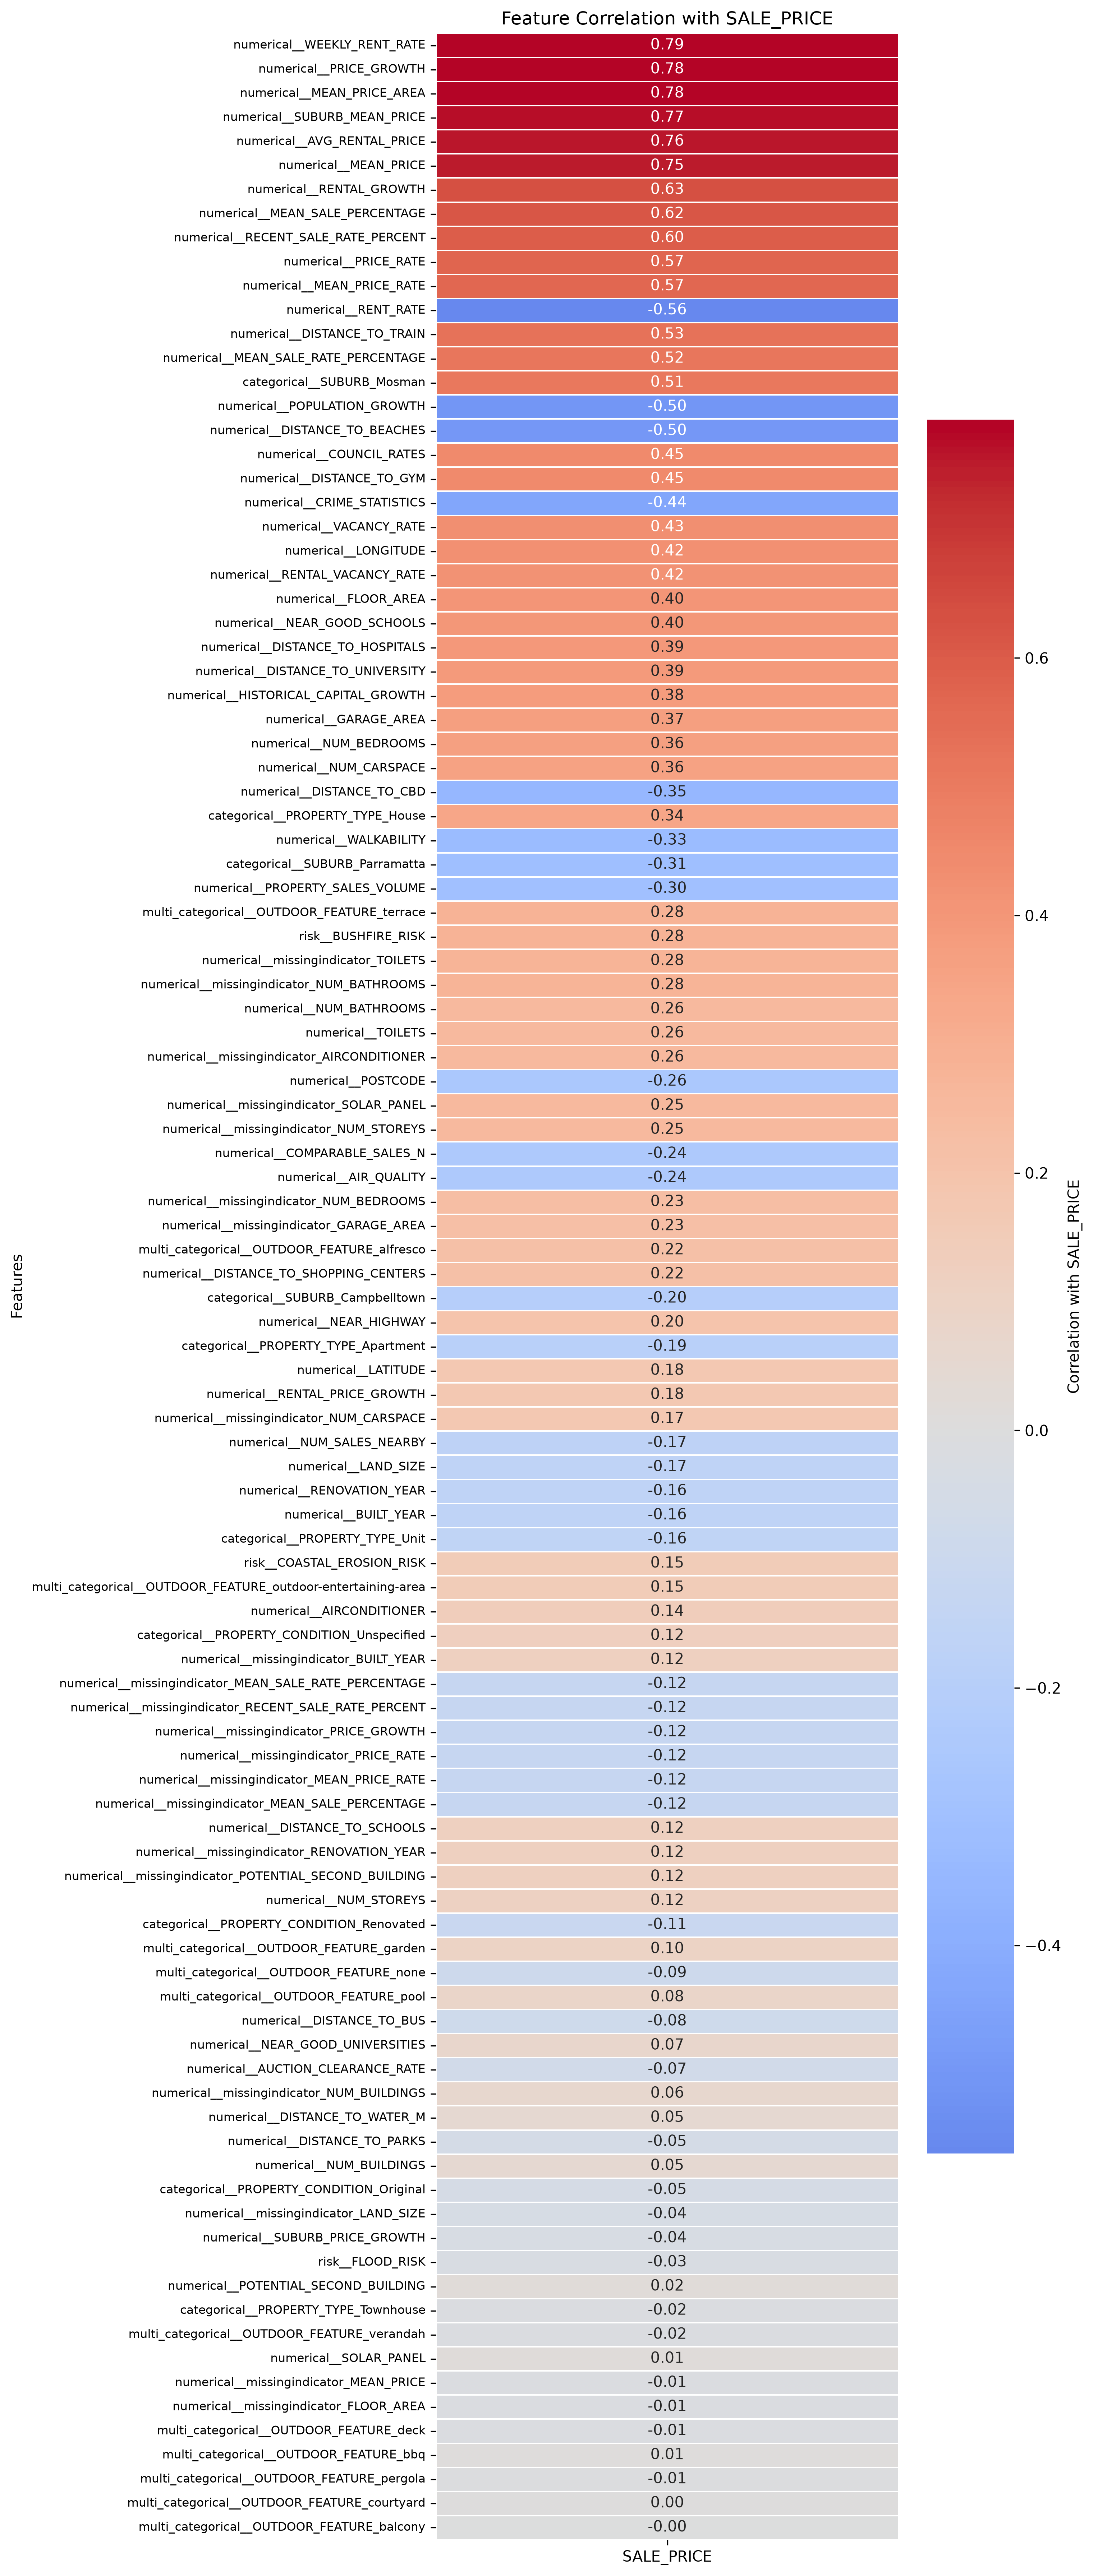

Multi Hot Encoder Matrix:
[[0 1 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 1 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 1 0 ... 0 0 0]
 [0 1 0 ... 0 0 0]]

Exploring Property Valuation dataset

Dataset dimensions: (150, 71)

Dataset feature type:
LAND_SIZE                       float64
FLOOR_AREA                      float64
NUM_BEDROOMS                    float64
NUM_CARSPACE                    float64
GARAGE_AREA                     float64
PROPERTY_TYPE                       str
NUM_STOREYS                     float64
BUILT_YEAR                      float64
PROPERTY_CONDITION                  str
RENOVATION_YEAR                 float64
OUTDOOR_FEATURE                     str
SOLAR_PANEL                     float64
AIRCONDITIONER                  float64
POTENTIAL_SECOND_BUILDING       float64
NUM_BUILDINGS                   float64
ADDRESS                             str
DISTANCE_TO_TRAIN               float64
DISTANCE_TO_BUS                 float64
DISTANCE_TO_SCHOOLS             float64
DI

In [3]:
def read_csv(csv_file: str):
    df = pd.read_csv(csv_file)
    return df

def data_exploration(df: pd.DataFrame, dataset_name: str):
    print(f"Exploring {dataset_name} dataset\n")
    print(f"Dataset dimensions: {df.shape}\n")
    # print(f"Dataset features:\n{df.columns}\n")
    print(f"Dataset feature type:\n{df.dtypes.to_string()}\n")
    print(f"Inspecting features with their missing values:\n{df.isnull().sum().to_string()}\n")
    missing = df.isnull().sum()
    print(f"Corresponding features with only their missing values:\n{missing[missing > 0].to_string()}\n")
    print(f"Number of features with missing values: {missing[missing > 0].count()}\n")
    print(f"Describing the dataset:\n{df.describe()}\n")

def preprocess(df: pd.DataFrame):
    multi_feature = "OUTDOOR_FEATURE"
    risk_features = ["FLOOD_RISK", "BUSHFIRE_RISK", "COASTAL_EROSION_RISK"]
    exclude_categorical = [multi_feature,"PREV_SALE_DATE","PREV_SALE_PRICE","SALE_DATE", "FLOOD_RISK", "BUSHFIRE_RISK", "COASTAL_EROSION_RISK"]

    numerical_features = df.select_dtypes(include=["int64", "float64"]).columns
    categorical_features = df.select_dtypes(include=["string", "category", "object"]).columns.drop(exclude_categorical, errors="ignore")


    numerical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ])

    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])

    multi_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", MultiHotEncoder(seperator=";")),
    ])

    risk_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(categories=[
            ["Nil", "Low", "Medium", "High"],
            ["Nil", "Low", "Medium", "High"],
            ["Nil", "Low", "Medium", "High"]
        ]))
    ])

    preprocessor = ColumnTransformer([
        ("numerical", numerical_transformer, numerical_features),
        ("categorical", categorical_transformer, categorical_features),
        ("multi_categorical", multi_transformer, [multi_feature]),
        ("risk", risk_transformer, risk_features)
    ])

    return preprocessor

def exploratory_analysis(transformed_inputs, outputs, preprocessor):
    feature_names = preprocessor.get_feature_names_out()
    transformed_df = pd.DataFrame(transformed_inputs, columns=feature_names, index= outputs.index)
    transformed_df["SALE_PRICE"] = outputs

    correlation = transformed_df.corr()["SALE_PRICE"].drop("SALE_PRICE")
    correlations = correlation.loc[correlation.abs().sort_values(ascending=False).index]
    print(f"Correlation:\n{correlations.to_string()}\n")

    correlation_df = correlations.to_frame(name="SALE_PRICE")

    plt.figure(figsize=(10, 24), dpi=300)

    sb.heatmap(correlation_df,cmap="coolwarm",center=0,annot=True,fmt=".2f",linewidths=0.5,cbar_kws={"label": "Correlation with SALE_PRICE"})

    plt.title("Feature Correlation with SALE_PRICE")
    plt.ylabel("Features")
    plt.xticks(rotation=0)
    plt.yticks(rotation=0, fontsize=8)

    plt.tight_layout()
    plt.show()


def main():
    df = read_csv("./dataset/the_sold_properties_V2.csv")
    df = add_price_features(df)

    inputs = df.drop(columns=["SALE_PRICE", "ADDRESS", "COMPARABLE_SALES"])
    outputs = df["SALE_PRICE"]

    preprocessor = preprocess(inputs)
    transformed_inputs = preprocessor.fit_transform(inputs)
    exploratory_analysis(transformed_inputs, outputs, preprocessor)

    multi_pipeline = preprocessor.named_transformers_["multi_categorical"]
    multi_hot_matrix = multi_pipeline.transform(inputs[["OUTDOOR_FEATURE"]])
    print(f"Multi Hot Encoder Matrix:\n{multi_hot_matrix}\n")
    data_exploration(df, "Property Valuation")

main()

## Data Understanding

### Price Distribution and Suburb Difference

Sale price summary:
count         150.00
mean      1290547.67
std       1463362.54
min        363000.00
25%        612750.00
50%        833500.00
75%       1203750.00
max      11650000.00

Skewness: 4.16



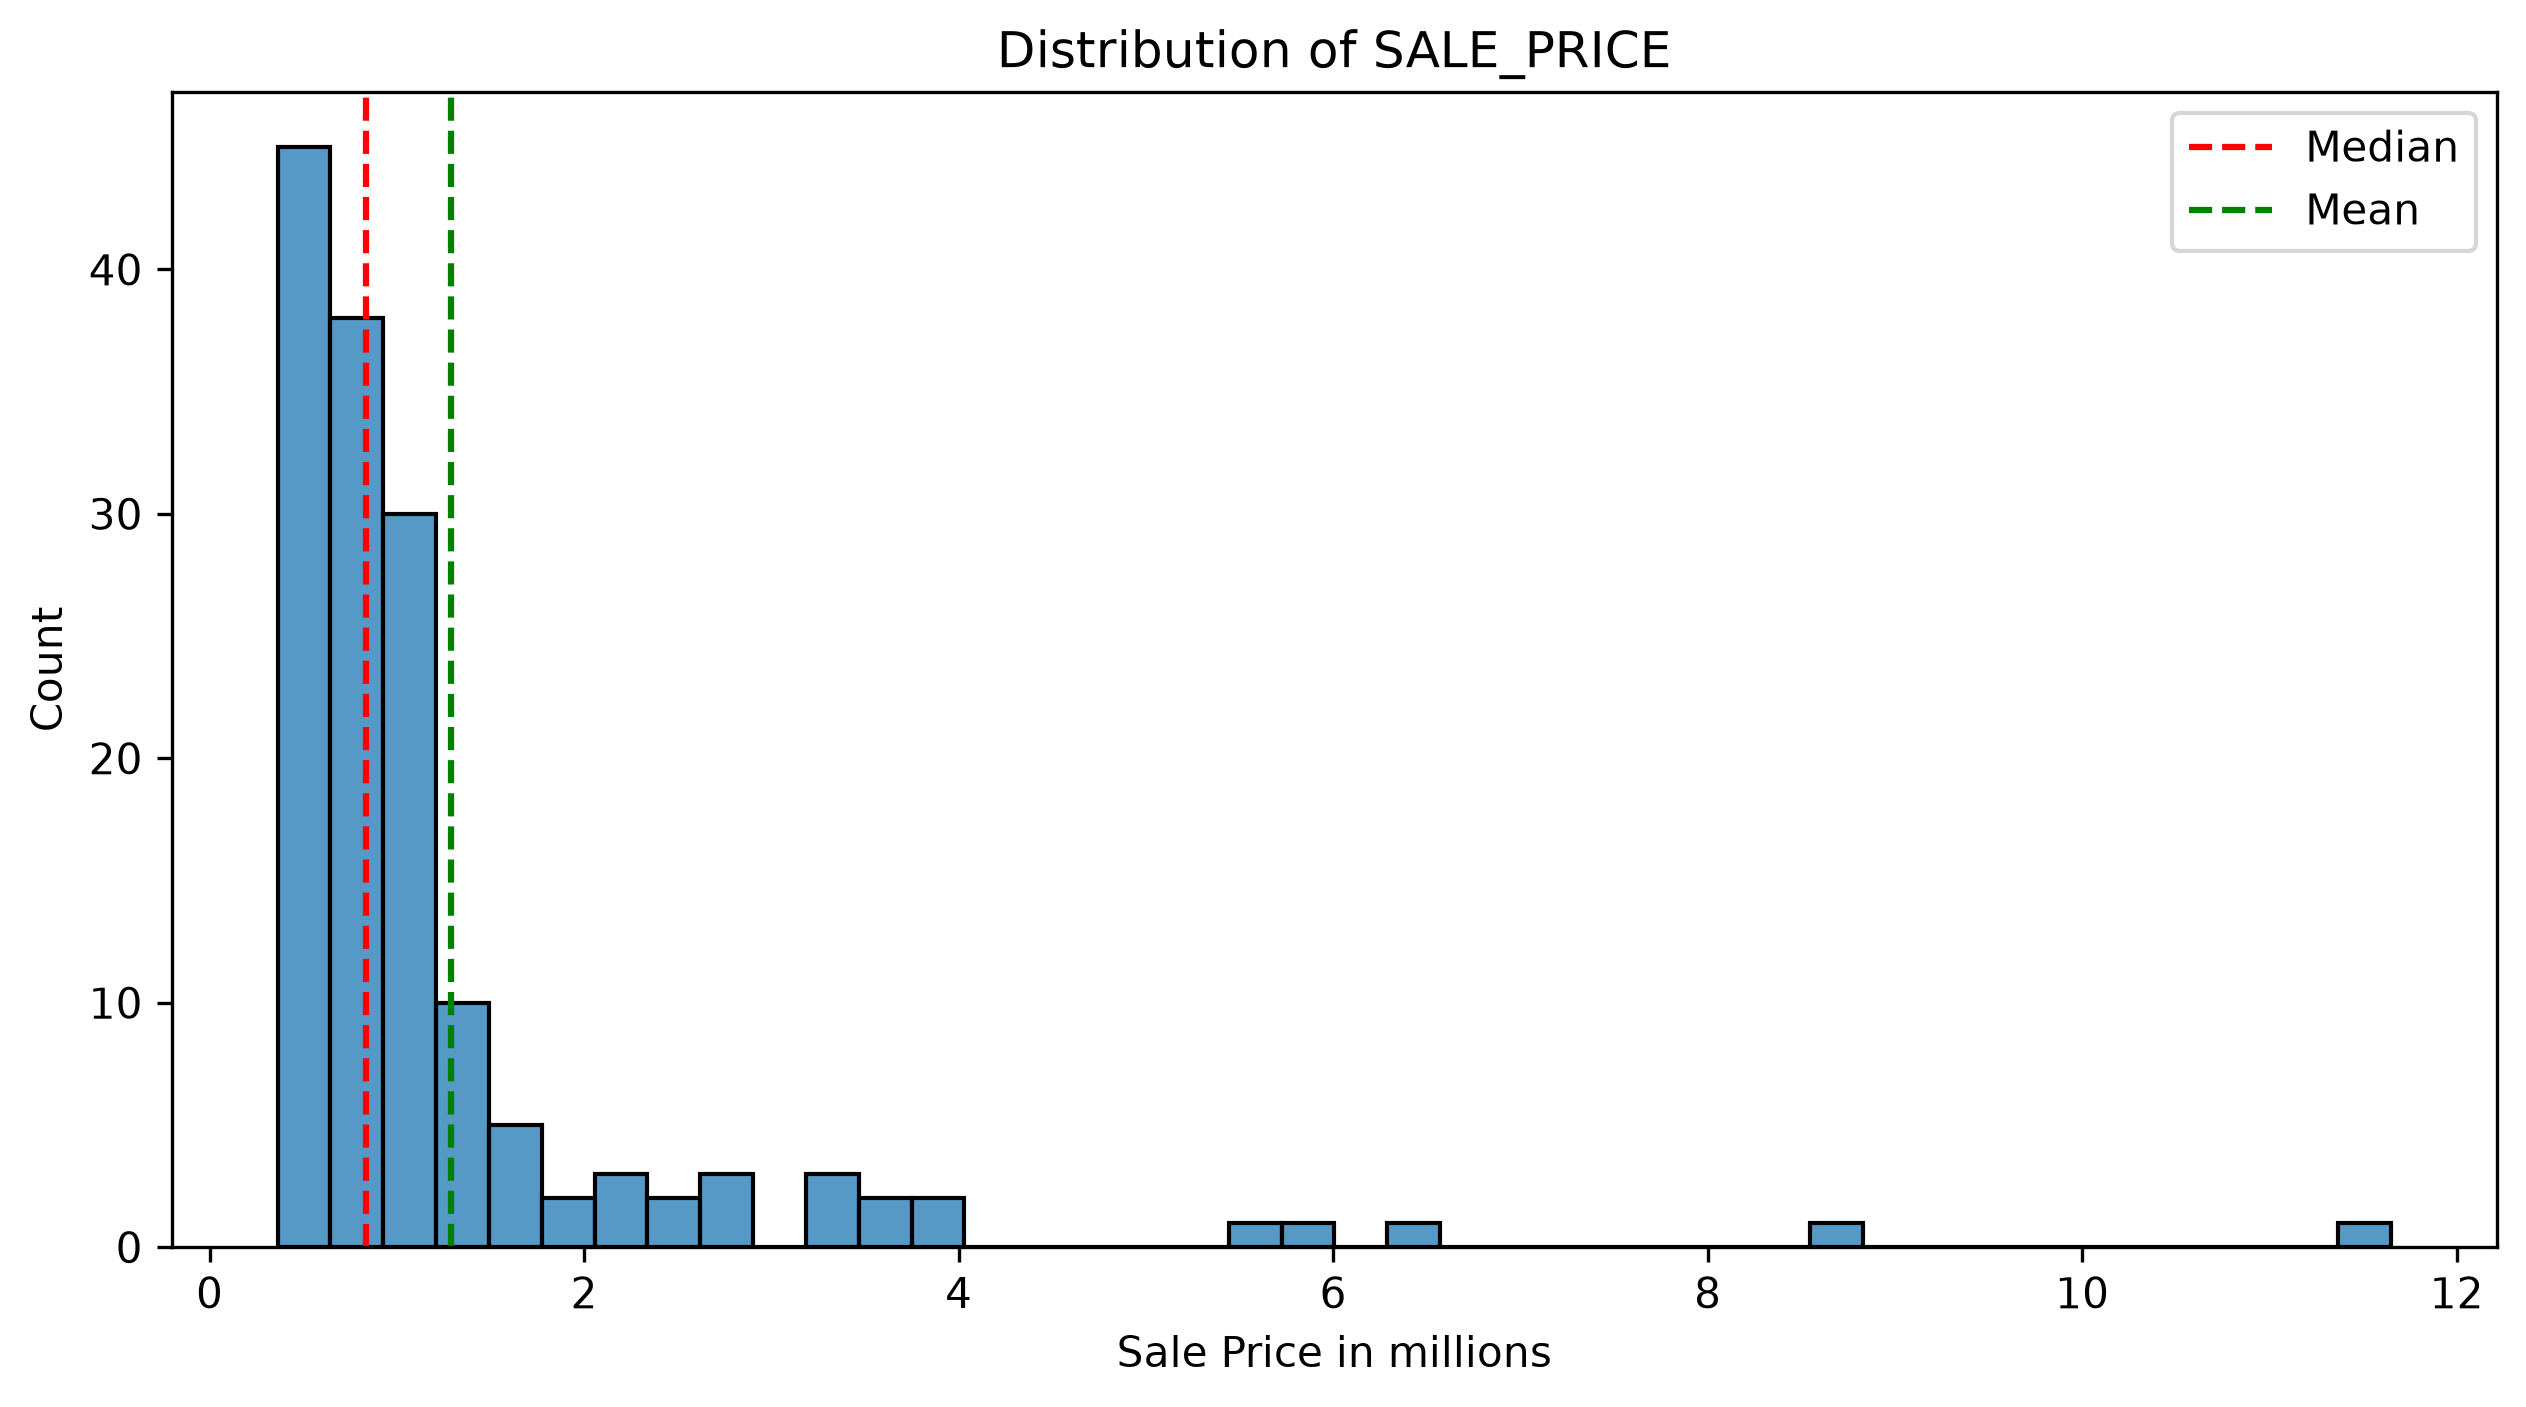

Sale price by suburb:
              count       mean         std       min       25%        50%        75%         max
SUBURB                                                                                          
Campbelltown   50.0   878323.0   327812.27  363000.0  610500.0   902500.0  1027500.0   1750000.0
Mosman         50.0  2335700.0  2155284.44  700000.0  992500.0  1450000.0  2887500.0  11650000.0
Parramatta     50.0   657620.0   249353.20  405000.0  547000.0   619000.0   680000.0   2080000.0

Sale price by suburb and property type:
                            count     median
SUBURB       PROPERTY_TYPE                  
Campbelltown Apartment          2   590000.0
             House             29   990000.0
             Townhouse          2   683797.5
             Unit              17   540000.0
Mosman       Apartment          1  1220000.0
             House              9  3700000.0
             Townhouse          1  2380000.0
             Unit              39  1310000.0
Pa

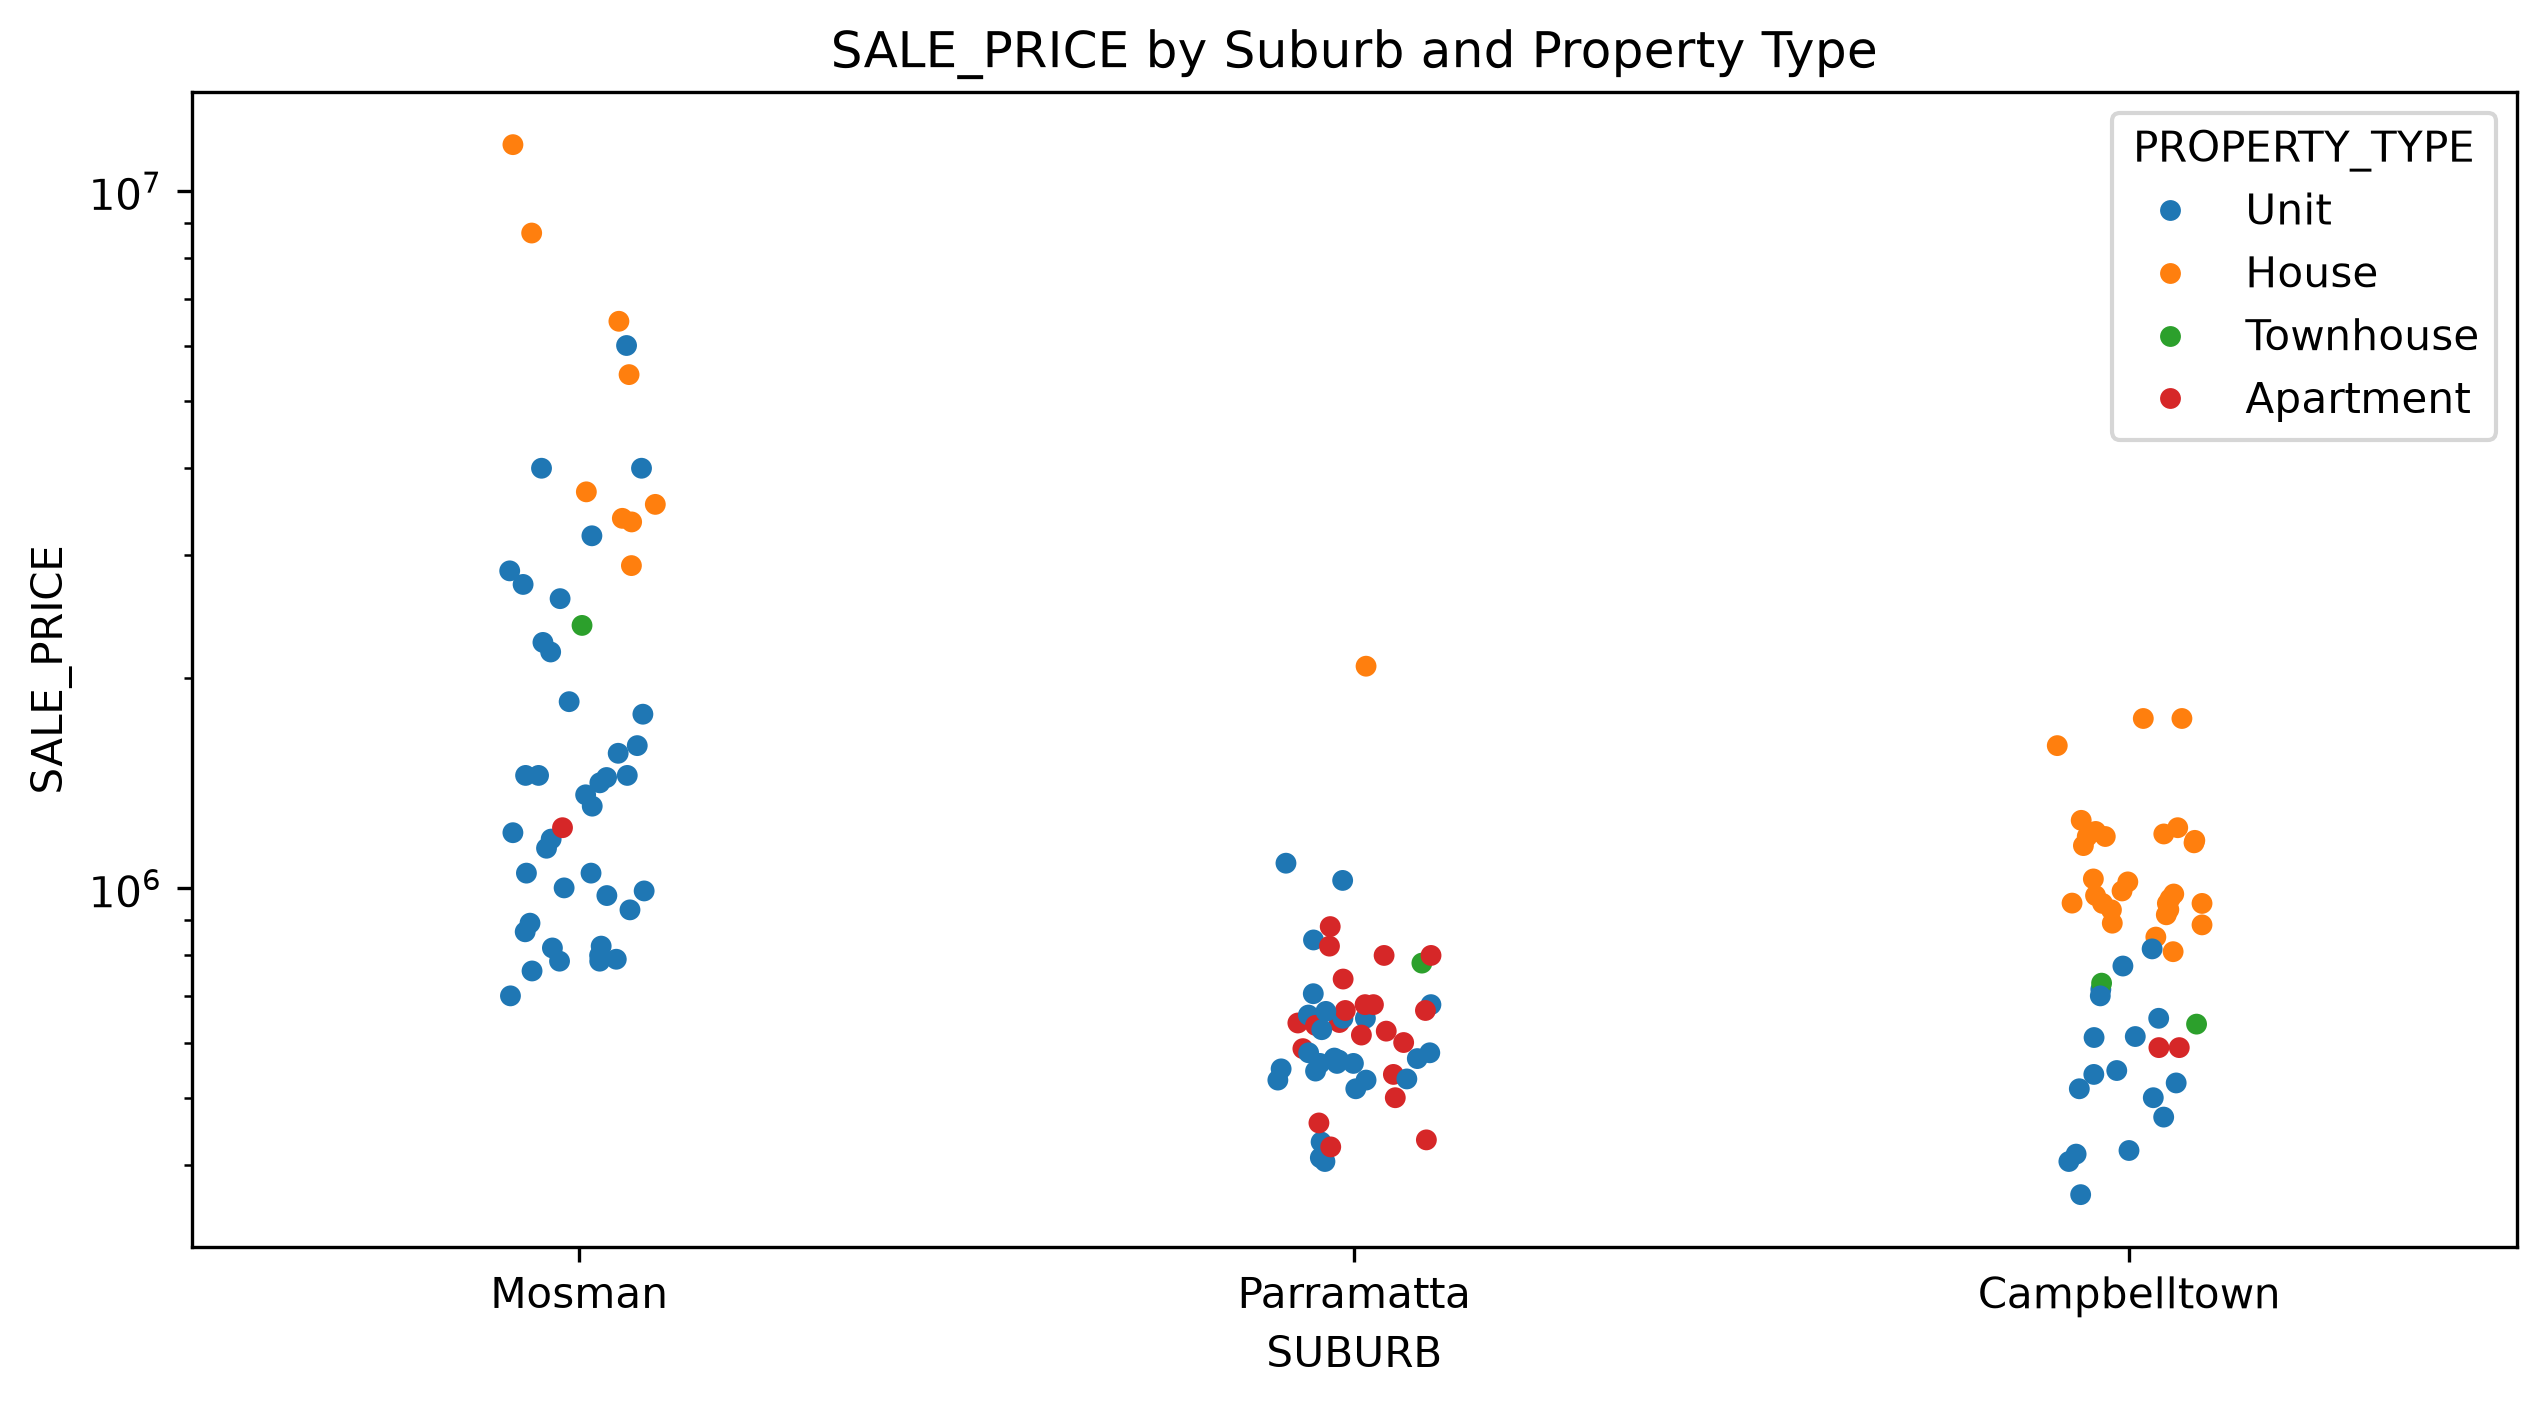

In [4]:
SUBURBS = ["Mosman", "Parramatta", "Campbelltown"]

def price_distribution(df: pd.DataFrame):
    prices = df["SALE_PRICE"]
    print(f"Sale price summary:\n{prices.describe().round(2).to_string()}\n")
    print(f"Skewness: {prices.skew():.2f}\n")

    plt.figure(figsize=(10, 5), dpi=300)
    sb.histplot(prices / 1000000, bins=40)
    plt.axvline(prices.median() / 1000000, color="red", linestyle="--", label="Median")
    plt.axvline(prices.mean() / 1000000, color="green", linestyle="--", label="Mean")
    plt.title("Distribution of SALE_PRICE")
    plt.xlabel("Sale Price in millions")
    plt.legend()
    plt.show()

def suburb_differences(df: pd.DataFrame):
    suburb_prices = df.groupby("SUBURB")["SALE_PRICE"].describe().round(2)
    print(f"Sale price by suburb:\n{suburb_prices.to_string()}\n")

    type_prices = df.groupby(["SUBURB", "PROPERTY_TYPE"])["SALE_PRICE"].agg(["count", "median"])
    print(f"Sale price by suburb and property type:\n{type_prices.to_string()}\n")

    plt.figure(figsize=(10, 5), dpi=300)
    sb.stripplot(data=df, x="SUBURB", y="SALE_PRICE", hue="PROPERTY_TYPE")
    plt.yscale("log")
    plt.title("SALE_PRICE by Suburb and Property Type")
    plt.show()

def price_distribution_suburb_differences():
    df = read_csv("./dataset/the_sold_properties_V2.csv")
    price_distribution(df)
    suburb_differences(df)

price_distribution_suburb_differences()

### Trend over time and outliers

Median sale price per month in 2026:
SUBURB      Campbelltown     Mosman  Parramatta  All Suburbs
SALE_MONTH                                                  
5                    NaN  2725000.0         NaN    2725000.0
6               940000.0  1450000.0         NaN    1175000.0
7               817500.0  1362500.0    638000.0     810000.0
8               940500.0   930000.0    611500.0     650000.0
9               950000.0  1450000.0    575000.0     642500.0

Yearly growth between previous sales (%):
              count  median
SUBURB                     
Campbelltown     28    7.82
Mosman           31    9.98
Parramatta       18    5.53



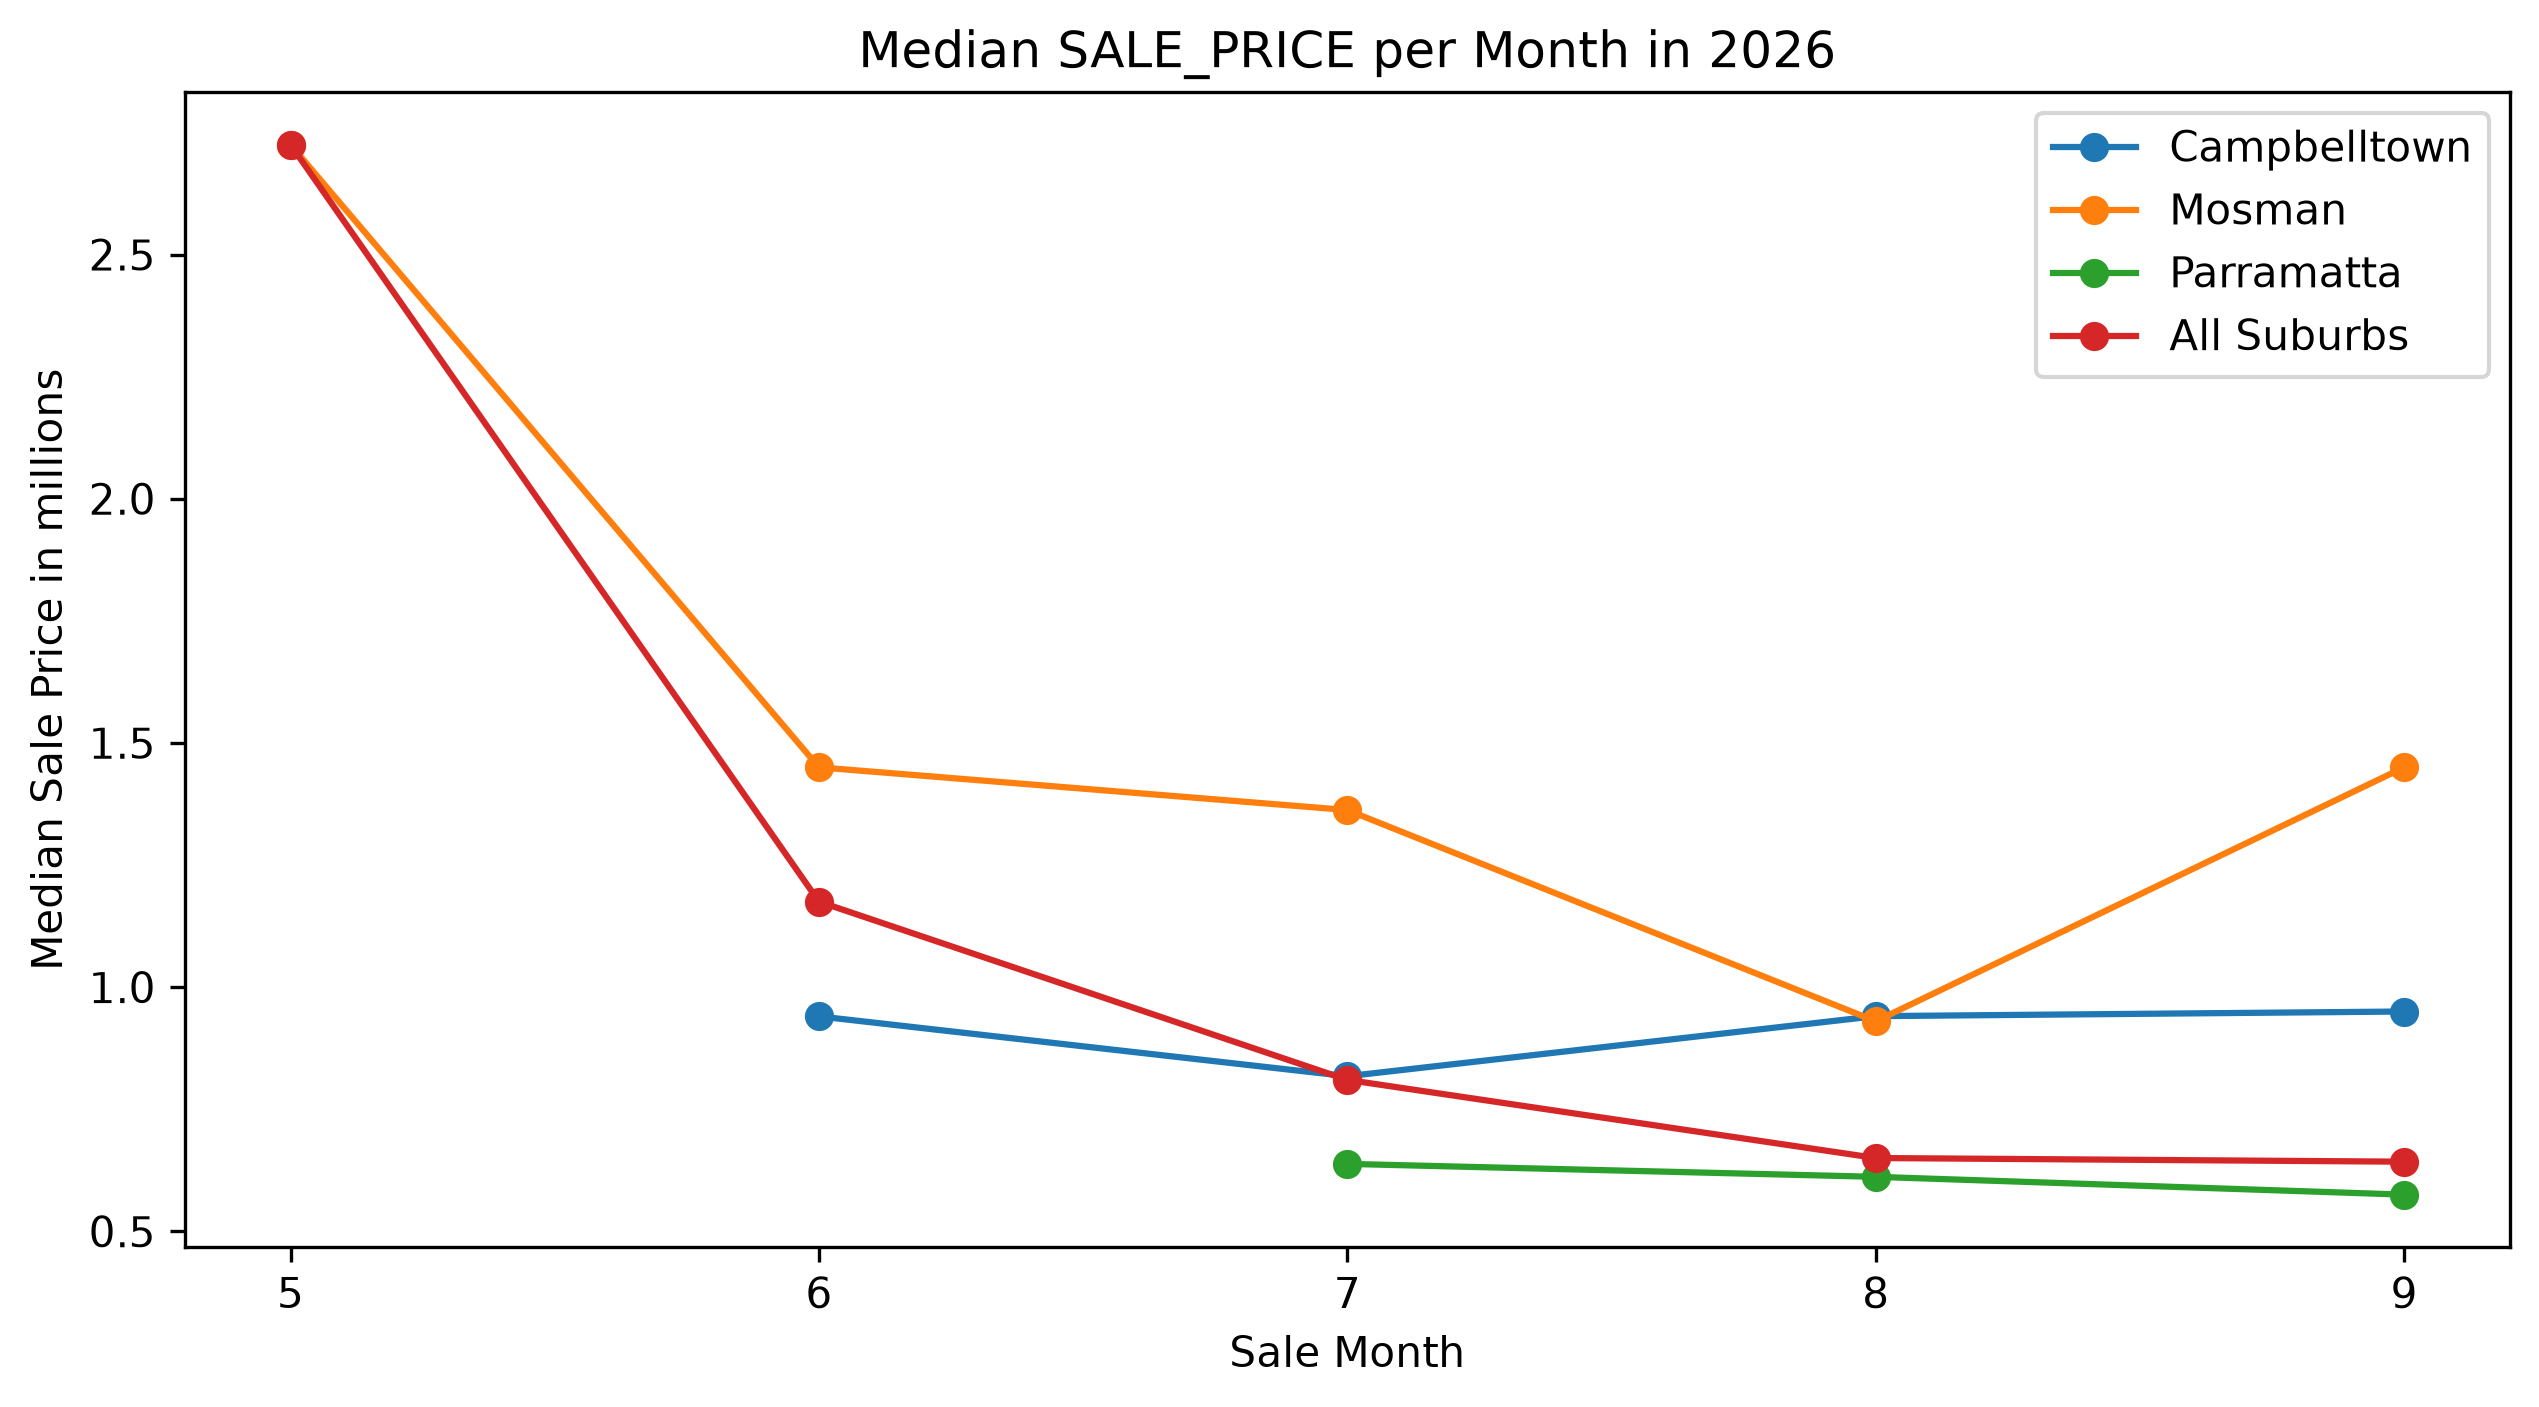


LAND_SIZE has 22 outliers
    Parramatta: 15
    Campbelltown: 7
    Unit: 17
    Apartment: 5

FLOOR_AREA has 13 outliers
    Campbelltown: 7
    Mosman: 5
    Parramatta: 1
    House: 10
    Unit: 2
    Townhouse: 1

BUILT_YEAR has 1 outliers
    Mosman: 1
    Unit: 1

RENOVATION_YEAR has 1 outliers
    Mosman: 1
    Unit: 1

DISTANCE_TO_BUS has 4 outliers
    Campbelltown: 4
    House: 4

DISTANCE_TO_SCHOOLS has 10 outliers
    Campbelltown: 8
    Mosman: 2
    House: 8
    Unit: 2

DISTANCE_TO_SHOPPING_CENTERS has 1 outliers
    Mosman: 1
    House: 1

DISTANCE_TO_HOSPITALS has 3 outliers
    Mosman: 3
    Unit: 2
    House: 1

DISTANCE_TO_PARKS has 8 outliers
    Campbelltown: 8
    House: 7
    Unit: 1

SALE_PRICE has 19 outliers
    Mosman: 19
    Unit: 9
    House: 9
    Townhouse: 1

RECENT_SALE_RATE_PERCENT has 7 outliers
    Mosman: 4
    Campbelltown: 2
    Parramatta: 1
    House: 4
    Unit: 3

COMPARABLE_SALES has 16 outliers
    Mosman: 16
    House: 9
    Unit: 6
    

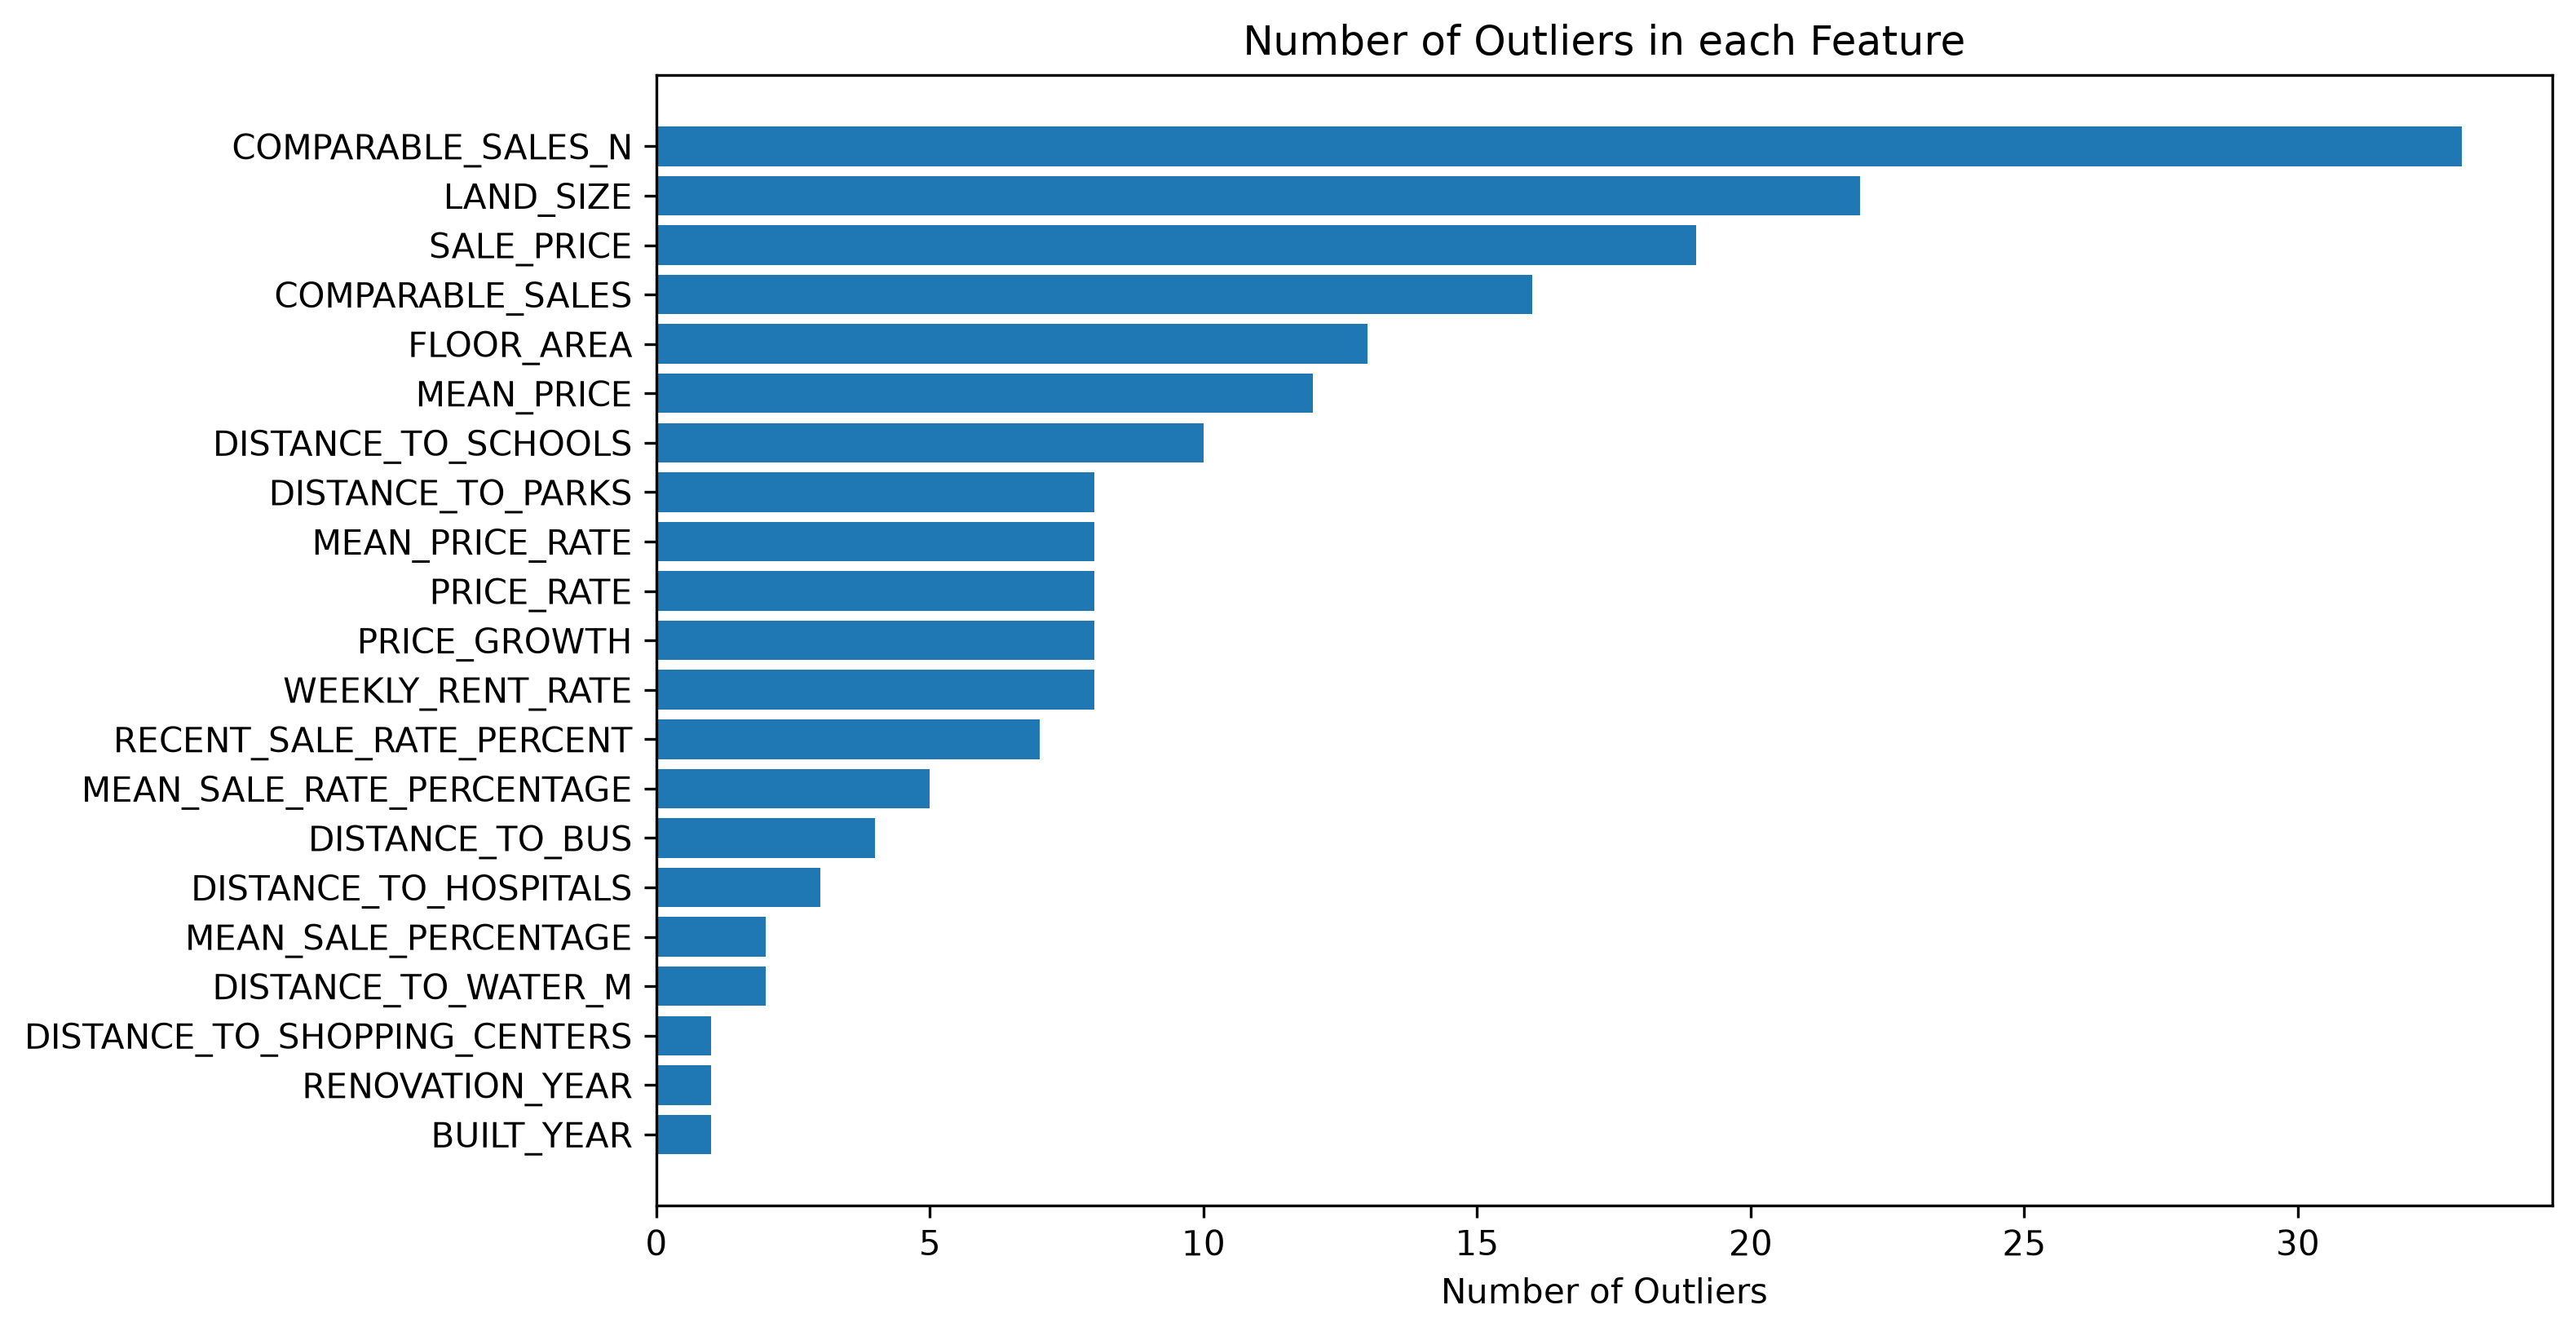

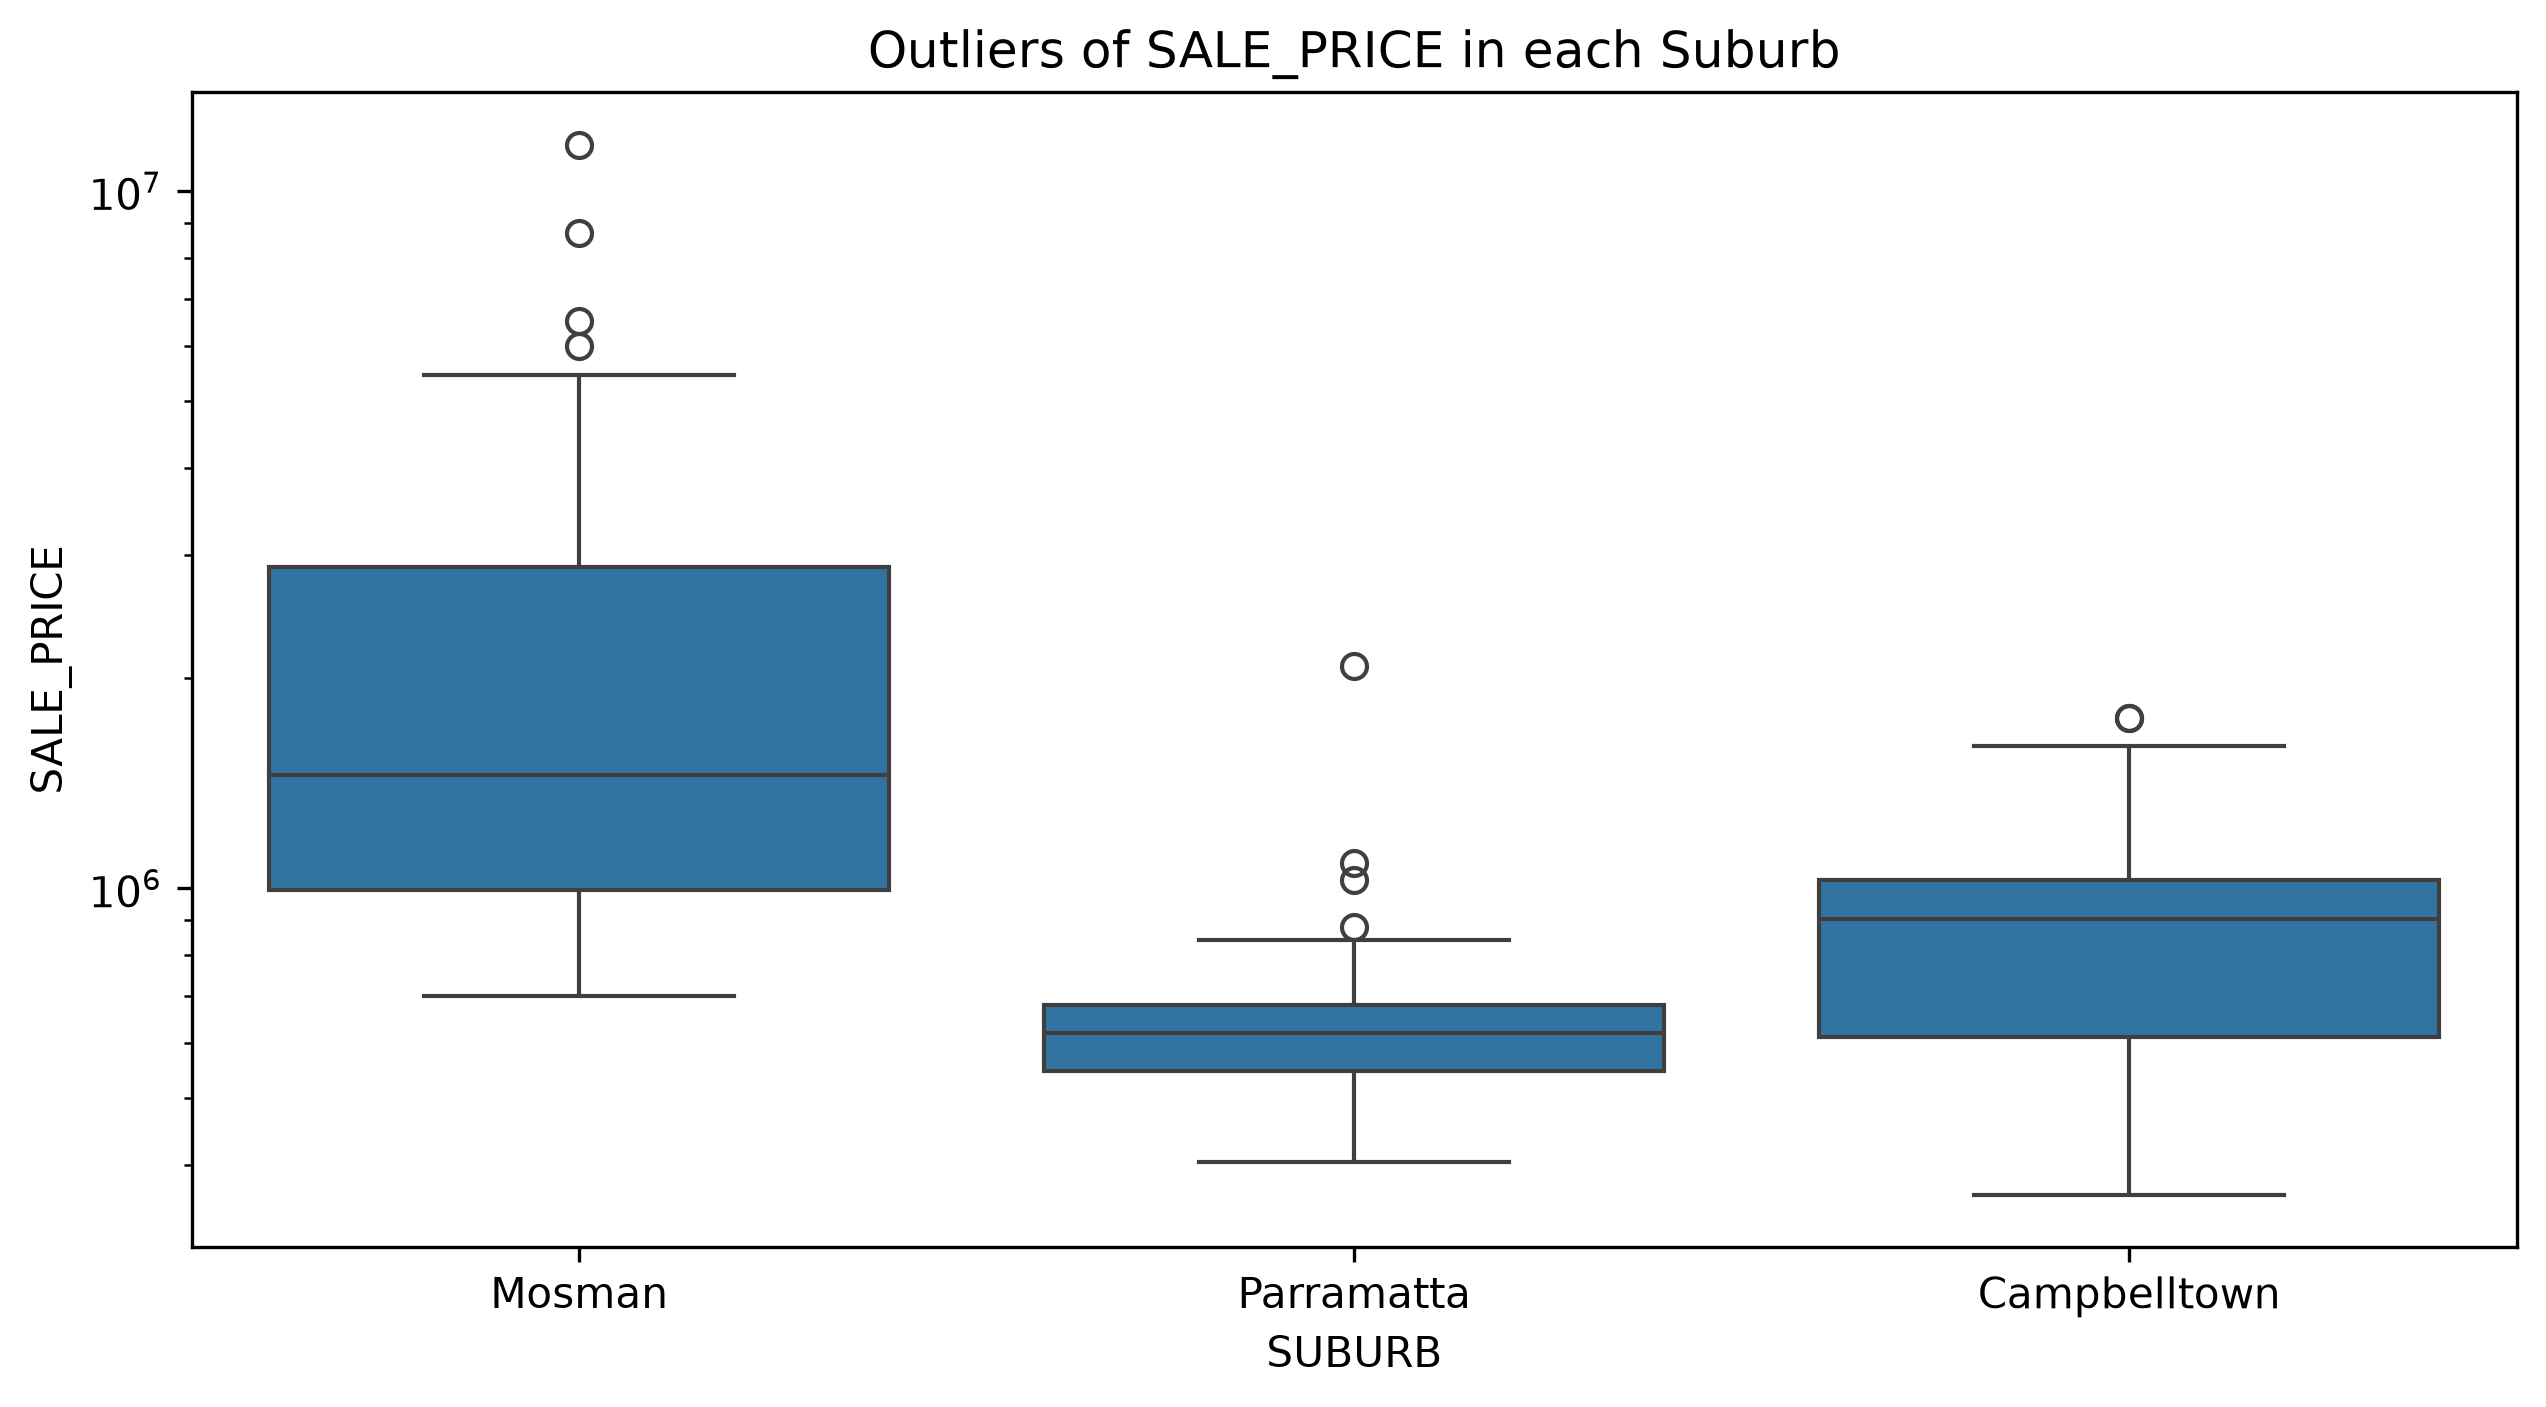

In [5]:
def trend_over_time(df: pd.DataFrame):
    df["SALE_MONTH"] = pd.to_datetime(df["SALE_DATE"]).dt.month

    monthly = df.pivot_table(index="SALE_MONTH", columns="SUBURB", values="SALE_PRICE", aggfunc="median")
    monthly["All Suburbs"] = df.groupby("SALE_MONTH")["SALE_PRICE"].median()
    print(f"Median sale price per month in 2026:\n{monthly.to_string()}\n")

    yearly_growth = df.groupby("SUBURB")["MEAN_SALE_RATE_PERCENTAGE"].agg(["count", "median"])
    print(f"Yearly growth between previous sales (%):\n{yearly_growth.round(2).to_string()}\n")

    plt.figure(figsize=(10, 5), dpi=300)
    for column in monthly.columns:
        plt.plot(monthly.index, monthly[column] / 1000000, marker="o", label=column)
    plt.xticks(monthly.index)
    plt.title("Median SALE_PRICE per Month in 2026")
    plt.xlabel("Sale Month")
    plt.ylabel("Median Sale Price in millions")
    plt.legend()
    plt.show()

def iqr_outliers(df: pd.DataFrame, feature: str):
    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)
    upper_bound = q3 + 1.5 * (q3 - q1)
    lower_bound = q1 - 1.5 * (q3 - q1)
    return df[(df[feature] > upper_bound) | (df[feature] < lower_bound)]

def find_outliers(df: pd.DataFrame):
    outlier_counts = {}
    for feature in df.select_dtypes(include=["int64", "float64"]).columns:
        if df[feature].nunique() > 10:
            outliers = iqr_outliers(df, feature)
            if len(outliers) > 0:
                outlier_counts[feature] = len(outliers)
                print(f"\n{feature} has {len(outliers)} outliers")
                for suburb, count in outliers["SUBURB"].value_counts().items():
                    print(f"    {suburb}: {count}")
                for property_type, count in outliers["PROPERTY_TYPE"].value_counts().items():
                    print(f"    {property_type}: {count}")

    print(f"\nThere were {len(outlier_counts)} feature outliers")

    features = ["ADDRESS", "PROPERTY_TYPE", "SALE_PRICE", "LAND_SIZE", "FLOOR_AREA", "NUM_BEDROOMS", "NUM_BATHROOMS"]
    for suburb in df["SUBURB"].unique():
        price_outliers = iqr_outliers(df[df["SUBURB"] == suburb], "SALE_PRICE")
        print(f"\n{suburb} SALE_PRICE outliers:\n{price_outliers[features].to_string(index=False)}")

    outlier_counts = pd.Series(outlier_counts).sort_values()
    plt.figure(figsize=(10, 6), dpi=300)
    plt.barh(outlier_counts.index, outlier_counts.values)
    plt.title("Number of Outliers in each Feature")
    plt.xlabel("Number of Outliers")
    plt.show()

    plt.figure(figsize=(10, 5), dpi=300)
    sb.boxplot(data=df, x="SUBURB", y="SALE_PRICE")
    plt.yscale("log")
    plt.title("Outliers of SALE_PRICE in each Suburb")
    plt.show()

def trend_and_outliers():
    df = read_csv("./dataset/the_sold_properties_V2.csv")
    df = add_price_features(df)
    trend_over_time(df)
    find_outliers(df)

trend_and_outliers()

## Building the Models

In [6]:
def random_forest(preprocessor, cross_validation):
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(n_estimators=100, random_state=42))
    ])

    grid_params = {
        "regressor__n_estimators": [100, 200, 300, 400, 500],
        "regressor__max_depth": [None, 3, 5, 7, 10, 15, 20, 25],
        "regressor__min_samples_split": [2, 5, 10],
        "regressor__min_samples_leaf": [1, 2, 4],
        "regressor__max_features": ["sqrt", 0.5, 1.0]
    }
    rf_search = GridSearchCV(
        estimator=model,
        param_grid=grid_params,
        scoring="neg_root_mean_squared_error",
        cv=cross_validation,
        n_jobs=-1,
        return_train_score=True
    )
    return rf_search

def svm(preprocessor, cross_validation):
    svm_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("scaler", StandardScaler()),
        ("svr", SVR())
    ])

    model = TransformedTargetRegressor(regressor=svm_pipeline, transformer=StandardScaler())

    grid_params = [
        {
            "regressor__svr__kernel": ["linear"],
            "regressor__svr__C": [0.1, 1, 10, 100],
            "regressor__svr__epsilon": [0.01, 0.1, 0.5]
        },
        {
            "regressor__svr__kernel": ["rbf"],
            "regressor__svr__C": [0.1, 1, 10, 100],
            "regressor__svr__gamma": ["scale", "auto", 0.01, 0.1],
            "regressor__svr__epsilon": [0.01, 0.1, 0.5]
        },
        {
            "regressor__svr__kernel": ["poly"],
            "regressor__svr__C": [0.1, 1, 10],
            "regressor__svr__gamma": ["scale", "auto"],
            "regressor__svr__degree": [2, 3, 4],
            "regressor__svr__epsilon": [0.01, 0.1, 0.5]
        },
        {
            "regressor__svr__kernel": ["sigmoid"],
            "regressor__svr__C": [0.1, 1, 10],
            "regressor__svr__gamma": ["scale", "auto"],
            "regressor__svr__epsilon": [0.01, 0.1, 0.5]
        }
    ]

    svm_search = GridSearchCV(
        estimator=model,
        param_grid=grid_params,
        scoring="neg_root_mean_squared_error",
        cv=cross_validation,
        n_jobs=-1,
        return_train_score=True
    )
    return svm_search

def xgboost(preprocessor, cross_validation):
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", XGBRegressor(n_estimators=100, random_state=42, learning_rate=0.1, max_depth=6, objective="reg:squarederror"))
    ])

    grid_params = {
        "regressor__n_estimators": [100, 200, 300, 400, 500],
        "regressor__max_depth": [3, 5, 7, 10, 15, 20, 25],
        "regressor__learning_rate": [0.01, 0.03, 0.05, 0.06, 0.09, 0.1, 0.2, 0.3, 0.4, 0.5],
        "regressor__subsample": [0.8, 1.0],
        "regressor__colsample_bytree": [0.8, 1.0],
    }
    xgb_search = GridSearchCV(
        estimator=model,
        param_grid=grid_params,
        scoring="neg_root_mean_squared_error",
        cv=cross_validation,
        n_jobs=-1,
        return_train_score=True
    )
    return xgb_search

def adaboost(preprocessor, cross_validation):
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", AdaBoostRegressor(n_estimators=100, random_state=42, learning_rate=0.1))
    ])
    grid_params = {
        "regressor__n_estimators": [50, 100, 200, 300, 400, 500],
        "regressor__learning_rate": [0.01, 0.03, 0.05, 0.06, 0.09, 0.1, 0.2, 0.3, 0.4, 0.5],
        "regressor__loss": ["linear", "square", "exponential"]
    }
    adaboost_search = GridSearchCV(
        estimator=model,
        param_grid=grid_params,
        scoring="neg_root_mean_squared_error",
        cv=cross_validation,
        n_jobs=-1,
        return_train_score=True
    )
    return adaboost_search

def gradient_boost(preprocessor, cross_validation):
    preprocessor.set_params(
        numerical__imputer__strategy="mean"
    )
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", GradientBoostingRegressor(n_estimators=100, random_state=42, learning_rate=0.1))
    ])
    grid_params = {
        "regressor__n_estimators": [100, 200, 300, 400, 500],
        "regressor__learning_rate": [0.01, 0.03, 0.05, 0.06, 0.09, 0.1, 0.2, 0.3, 0.4, 0.5],
        "regressor__max_depth": [None, 3, 5, 7, 10, 15, 20, 25],
        "regressor__min_samples_split": [2, 5, 10],
        "regressor__min_samples_leaf": [1, 2, 4]
    }
    gradient_search = GridSearchCV(
        estimator=model,
        param_grid=grid_params,
        scoring="neg_root_mean_squared_error",
        cv=cross_validation,
        n_jobs=-1,
        return_train_score=True
    )
    return gradient_search

def decision_tree(preprocessor, cross_validation):
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", DecisionTreeRegressor(random_state=42, max_depth=6))
    ])

    grid_params = {
        "regressor__max_depth": [None, 3, 5, 7, 10, 15, 20, 25],
        "regressor__min_samples_split": [2, 5, 10],
        "regressor__min_samples_leaf": [1, 2, 4],
        "regressor__max_features": [None, "sqrt", 0.5]
    }
    decision_tree_search = GridSearchCV(
        estimator=model,
        param_grid=grid_params,
        scoring="neg_root_mean_squared_error",
        cv=cross_validation,
        n_jobs=-1,
        return_train_score=True
    )
    return decision_tree_search

def evaluate_model(model, train_inputs, test_inputs, train_outputs, test_outputs, title: str = "Evaluating Regression Models"):
    model.fit(train_inputs, train_outputs)
    cv_results = pd.DataFrame(model.cv_results_)

    predictions = model.predict(test_inputs)

    mae = mean_absolute_error(test_outputs, predictions)
    rmse = np.sqrt(mean_squared_error(test_outputs, predictions))
    r2 = r2_score(test_outputs, predictions)
    mse = mean_squared_error(test_outputs, predictions)

    cv_results["mean_train_rmse"] = -cv_results["mean_train_score"]

    print(title + "\n")

    print("Cross Validation Results:")
    print(cv_results[["params", "mean_train_rmse", "mean_test_score", "std_train_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score").head(10).to_string(index=False) + "\n")
    print(f"Best Parameters: {model.best_params_}")

    print(f"Best CV RMSE: ${-model.best_score_:,.2f}")

    print("\nTest Prediction Evaluation:\n")
    print(f"Mean Square Error: {mse}")
    print(f"Mean Absolute Error: {mae}")
    print(f"Root Mean Square Error: {rmse}")
    print(f"R^2: {r2}\n")

    return mse, mae, rmse, r2

def execute_model_evaluations():
    df = read_csv("./dataset/the_sold_properties_V2.csv")
    df = add_price_features(df)

    inputs = df.drop(columns=["SALE_PRICE", "ADDRESS", "COMPARABLE_SALES", "COMPARABLE_SALES_N"])
    outputs = df["SALE_PRICE"]

    preprocessor_rf = preprocess(inputs)
    preprocessor_svm = preprocess(inputs)
    preprocessor_xgb = preprocess(inputs)
    preprocessor_adab = preprocess(inputs)
    preprocessor_gb = preprocess(inputs)
    preprocessor_decitree = preprocess(inputs)

    inputs["OUTDOOR_FEATURE"] = inputs["OUTDOOR_FEATURE"].fillna("unstated")

    train_inputs, test_inputs, train_outputs, test_outputs = train_test_split(inputs, outputs, test_size=0.25, random_state=42)

    cross_validation = KFold(n_splits=5, shuffle=True, random_state=42)
    rf_model = random_forest(preprocessor_rf, cross_validation)
    svm_model = svm(preprocessor_svm, cross_validation)
    xgb_model = xgboost(preprocessor_xgb, cross_validation)
    adaboost_model = adaboost(preprocessor_adab, cross_validation)
    gradientboost_model = gradient_boost(preprocessor_gb, cross_validation)
    decision_tree_model = decision_tree(preprocessor_decitree, cross_validation)

    rf_eval =  evaluate_model(rf_model, train_inputs, test_inputs, train_outputs, test_outputs, "Evaluating Random Forest")
    svm_eval = evaluate_model(svm_model, train_inputs, test_inputs, train_outputs, test_outputs, "Evaluating SVM")
    xgb_eval = evaluate_model(xgb_model, train_inputs, test_inputs, train_outputs, test_outputs, "Evaluating XGB")
    adaboost_eval = evaluate_model(adaboost_model, train_inputs, test_inputs, train_outputs, test_outputs, "Evaluating AdaBoost")
    gradientboost_eval = evaluate_model(gradientboost_model, train_inputs, test_inputs, train_outputs, test_outputs, "Evaluating Gradient Boost")
    deci_tree =  evaluate_model(decision_tree_model, train_inputs, test_inputs, train_outputs, test_outputs, "Evaluating Decision Tree")

execute_model_evaluations()

Evaluating Random Forest

Cross Validation Results:
                                                                                                                                                             params  mean_train_rmse  mean_test_score  std_train_score  std_test_score  rank_test_score
  {'regressor__max_depth': 10, 'regressor__max_features': 1.0, 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 300}    417768.741085   -615001.743669     30186.958660   338354.197903                1
  {'regressor__max_depth': 25, 'regressor__max_features': 1.0, 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 300}    417886.753763   -615597.459833     29861.721348   339251.465282                2
  {'regressor__max_depth': 15, 'regressor__max_features': 1.0, 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 300}    417886.753763   -615597.459833     29

In [7]:
def svm(preprocessor, cross_validation):
    svm_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("scaler", StandardScaler()),
        ("svr", SVR())
    ])

    model = TransformedTargetRegressor(regressor=svm_pipeline, transformer=StandardScaler())

    grid_params = [
        {
            "regressor__svr__kernel": ["linear"],
            "regressor__svr__C": [0.1, 1, 10, 100],
            "regressor__svr__epsilon": [0.01, 0.1, 0.5]
        },
        {
            "regressor__svr__kernel": ["rbf"],
            "regressor__svr__C": [0.1, 1, 10, 100],
            "regressor__svr__gamma": ["scale", "auto", 0.01, 0.1],
            "regressor__svr__epsilon": [0.01, 0.1, 0.5]
        },
        {
            "regressor__svr__kernel": ["poly"],
            "regressor__svr__C": [0.1, 1, 10],
            "regressor__svr__gamma": ["scale", "auto"],
            "regressor__svr__degree": [2, 3, 4],
            "regressor__svr__epsilon": [0.01, 0.1, 0.5]
        },
        {
            "regressor__svr__kernel": ["sigmoid"],
            "regressor__svr__C": [0.1, 1, 10],
            "regressor__svr__gamma": ["scale", "auto"],
            "regressor__svr__epsilon": [0.01, 0.1, 0.5]
        }
    ]

    svm_search = GridSearchCV(
        estimator=model,
        param_grid=grid_params,
        scoring="neg_root_mean_squared_error",
        cv=cross_validation,
        n_jobs=-1,
        return_train_score=True
    )
    return svm_search

def xgboost(preprocessor, cross_validation):
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", XGBRegressor(n_estimators=100, random_state=42, learning_rate=0.1, max_depth=6, objective="reg:squarederror"))
    ])

    grid_params = {
        "regressor__n_estimators": [100, 200, 300, 400, 500],
        "regressor__max_depth": [3, 5, 7, 10, 15, 20, 25],
        "regressor__learning_rate": [0.01, 0.03, 0.05, 0.06, 0.09, 0.1, 0.2, 0.3, 0.4, 0.5],
        "regressor__subsample": [0.8, 1.0],
        "regressor__colsample_bytree": [0.8, 1.0],
    }
    xgb_search = GridSearchCV(
        estimator=model,
        param_grid=grid_params,
        scoring="neg_root_mean_squared_error",
        cv=cross_validation,
        n_jobs=-1,
        return_train_score=True
    )
    return xgb_search

def execute_model_evaluations():
    df = read_csv("./dataset/the_sold_properties_V2.csv")
    df = add_price_features(df)

    inputs = df.drop(columns=["SALE_PRICE", "ADDRESS"])
    outputs = df["SALE_PRICE"]

    preprocessor_svm = preprocess(inputs)
    preprocessor_xgb = preprocess(inputs)
    preprocessor_xgb.set_params(
        numerical__imputer__strategy="mean"
    )

    inputs["OUTDOOR_FEATURE"] = inputs["OUTDOOR_FEATURE"].fillna("unstated")

    train_inputs, test_inputs, train_outputs, test_outputs = train_test_split(inputs, outputs, test_size=0.25, random_state=42)

    cross_validation = KFold(n_splits=5, shuffle=True, random_state=42)
    svm_model = svm(preprocessor_svm, cross_validation)
    xgb_model = xgboost(preprocessor_xgb, cross_validation)

    svm_eval = evaluate_model(svm_model, train_inputs, test_inputs, train_outputs, test_outputs, "Evaluating SVM")
    xgb_eval = evaluate_model(xgb_model, train_inputs, test_inputs, train_outputs, test_outputs, "Evaluating XGB")

execute_model_evaluations()

Evaluating SVM

Cross Validation Results:
                                                                                                                                                     params  mean_train_rmse  mean_test_score  std_train_score  std_test_score  rank_test_score
  {'regressor__svr__C': 1, 'regressor__svr__degree': 2, 'regressor__svr__epsilon': 0.1, 'regressor__svr__gamma': 'scale', 'regressor__svr__kernel': 'poly'}    161955.017455   -635025.153632     22461.376835   321883.113413                1
   {'regressor__svr__C': 1, 'regressor__svr__degree': 2, 'regressor__svr__epsilon': 0.1, 'regressor__svr__gamma': 'auto', 'regressor__svr__kernel': 'poly'}    163829.639874   -636229.335678     23004.931117   321131.895072                2
 {'regressor__svr__C': 1, 'regressor__svr__degree': 2, 'regressor__svr__epsilon': 0.01, 'regressor__svr__gamma': 'scale', 'regressor__svr__kernel': 'poly'}    127228.391018   -637438.917460     37014.513538   322912.331721                

## Model Deployment

In [8]:
def train_random_forest(preprocessor, train_inputs, train_outputs):
    rf_model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(n_estimators=500, max_depth=3, max_features=0.5, min_samples_leaf=2, min_samples_split=2, random_state=42))
    ])
    rf_model.fit(train_inputs, train_outputs)
    return rf_model

def train_svm(preprocessor, train_inputs, train_outputs):
    svm_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("scaler", StandardScaler()),
        ("regressor", SVR(kernel="poly", C=1, degree=2, epsilon=0.1, gamma="scale"))
    ])

    model = TransformedTargetRegressor(regressor=svm_pipeline, transformer=StandardScaler())
    model.fit(train_inputs, train_outputs)
    return model

def train_gradient_boost(preprocessor, train_inputs, train_outputs):
    preprocessor.set_params(numerical__imputer__strategy="mean")
    gb_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", GradientBoostingRegressor(learning_rate=0.3, max_depth=7, min_samples_leaf=2, min_samples_split=10, n_estimators=400, random_state=42))
    ])
    gb_pipeline.fit(train_inputs, train_outputs)
    return gb_pipeline

def predict_sale_prices(models, property_inputs, property_outputs):
    model_predictions = {}
    for name, model in models.items():
        prediction = model.predict(property_inputs)[0]
        model_predictions[name] = prediction

    occurred_output = property_outputs.iloc[0]
    return model_predictions, occurred_output

def models_predict():
    df = read_csv("./dataset/the_sold_properties_V2.csv")
    df = add_price_features(df)

    inputs = df.drop(columns=["SALE_PRICE", "ADDRESS", "COMPARABLE_SALES"])
    outputs = df["SALE_PRICE"]

    preprocessor = preprocess(inputs)
    train_inputs, test_inputs, train_outputs, test_outputs = train_test_split(inputs, outputs, test_size=1, random_state=42)

    ## Train the models!
    rf_model = train_random_forest(preprocessor, train_inputs, train_outputs)
    svm_model = train_svm(preprocessor, train_inputs, train_outputs)
    gb_model = train_gradient_boost(preprocessor, train_inputs, train_outputs)

    models = {
        "Random Forest": rf_model,
        "SVM": svm_model,
        "Gradient Boost": gb_model
    }
    predictions, actual_price = predict_sale_prices(models, test_inputs, test_outputs)

    for model, prediction in predictions.items():
        difference = actual_price - prediction
        absolute_error = abs(difference)
        percentage_error = absolute_error / actual_price * 100

        print(f"{model} predicted ${prediction:.2f}")
        print(f"Difference to the actual price: ${difference:.2f}")
        print(f"Absolute error: ${abs(difference):.2f}")
        print(f"Percentage error: {percentage_error:.2f}%\n")

    print(f"Actual price ${actual_price:.2f}")

models_predict()

Random Forest predicted $661475.92
Difference to the actual price: $-4475.92
Absolute error: $4475.92
Percentage error: 0.68%

SVM predicted $825816.65
Difference to the actual price: $-168816.65
Absolute error: $168816.65
Percentage error: 25.70%

Gradient Boost predicted $639684.37
Difference to the actual price: $17315.63
Absolute error: $17315.63
Percentage error: 2.64%

Actual price $657000.00


In [9]:
def predict_sale_prices(models, property_inputs, property_outputs):
    model_predictions = {}

    for name, model in models.items():
        predictions = model.predict(property_inputs)
        model_predictions[name] = predictions

    return model_predictions, property_outputs

def models_predict():
    df = read_csv("./dataset/the_sold_properties_V2.csv")
    df = add_price_features(df)

    inputs = df.drop(columns=["SALE_PRICE", "ADDRESS", "COMPARABLE_SALES"])
    outputs = df["SALE_PRICE"]

    train_inputs, test_inputs, train_outputs, test_outputs = train_test_split(
        inputs, outputs, test_size=3, random_state=42
    )

    rf_preprocessor = preprocess(inputs)
    svm_preprocessor = preprocess(inputs)
    gb_preprocessor = preprocess(inputs)

    rf_preprocessor.set_params(
        numerical__imputer__strategy="median",
        numerical__imputer__add_indicator=True
    )

    svm_preprocessor.set_params(
        numerical__imputer__strategy="median",
        numerical__imputer__add_indicator=True
    )

    gb_preprocessor.set_params(
        numerical__imputer__strategy="mean",
        numerical__imputer__add_indicator=True
    )

    rf_model = train_random_forest(
        rf_preprocessor, train_inputs, train_outputs
    )

    svm_model = train_svm(
        svm_preprocessor, train_inputs, train_outputs
    )

    gb_model = train_gradient_boost(
        gb_preprocessor, train_inputs, train_outputs
    )

    models = {
        "Random Forest": rf_model,
        "SVM": svm_model,
        "Gradient Boost": gb_model
    }

    predictions, actual_prices = predict_sale_prices(
        models,
        test_inputs,
        test_outputs
    )

    for model, model_predictions in predictions.items():
        print(f"\n{model}\n")

        for i, prediction in enumerate(model_predictions):
            actual_price = actual_prices.iloc[i]

            difference = actual_price - prediction
            absolute_error = abs(difference)
            percentage_error = absolute_error / actual_price * 100

            print(f"Property {i + 1}")
            print(f"Predicted price: ${prediction:,.2f}")
            print(f"Actual price: ${actual_price:,.2f}")
            print(f"Difference: ${difference:,.2f}")
            print(f"Absolute error: ${absolute_error:,.2f}")
            print(f"Percentage error: {percentage_error:.2f}%\n")

models_predict()


Random Forest

Property 1
Predicted price: $668,757.49
Actual price: $657,000.00
Difference: $-11,757.49
Absolute error: $11,757.49
Percentage error: 1.79%

Property 2
Predicted price: $1,269,121.67
Actual price: $1,310,000.00
Difference: $40,878.33
Absolute error: $40,878.33
Percentage error: 3.12%

Property 3
Predicted price: $818,145.68
Actual price: $405,000.00
Difference: $-413,145.68
Absolute error: $413,145.68
Percentage error: 102.01%


SVM

Property 1
Predicted price: $826,868.78
Actual price: $657,000.00
Difference: $-169,868.78
Absolute error: $169,868.78
Percentage error: 25.86%

Property 2
Predicted price: $1,144,089.92
Actual price: $1,310,000.00
Difference: $165,910.08
Absolute error: $165,910.08
Percentage error: 12.66%

Property 3
Predicted price: $850,571.02
Actual price: $405,000.00
Difference: $-445,571.02
Absolute error: $445,571.02
Percentage error: 110.02%


Gradient Boost

Property 1
Predicted price: $650,801.04
Actual price: $657,000.00
Difference: $6,198.96
A

## Saving training data

In [10]:
import joblib
from pathlib import Path

def save_random_forest_td(train_inputs, train_outputs):
    preprocessor = preprocess(train_inputs)
    rf_model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(n_estimators=500, max_depth=3, max_features=0.5, min_samples_leaf=2, min_samples_split=2, random_state=42))
    ])
    rf_model.fit(train_inputs, train_outputs)
    joblib.dump(rf_model, "./saved_models/random_forest.pkl")

def save_svm_td(train_inputs, train_outputs):
    preprocessor = preprocess(train_inputs)
    svm_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("scaler", StandardScaler()),
        ("regressor", SVR(kernel="poly", C=1, degree=2, epsilon=0.1, gamma="scale"))
    ])

    model = TransformedTargetRegressor(regressor=svm_pipeline, transformer=StandardScaler())
    model.fit(train_inputs, train_outputs)
    joblib.dump(model, "./saved_models/svm.pkl")


def save_xgboost_td(train_inputs, train_outputs):
    preprocessor = preprocess(train_inputs)
    preprocessor.set_params(
        numerical__imputer__strategy="mean",
        numerical__imputer__add_indicator=True,
    )

    xgb_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", XGBRegressor(colsample_bytree=0.8, learning_rate=0.4, max_depth=3, n_estimators=400, subsample=1.0, random_state=42))
    ])
    xgb_pipeline.fit(train_inputs, train_outputs)
    joblib.dump(xgb_pipeline, "./saved_models/gradient_boost.pkl")


def save_decision_tree(train_inputs, train_outputs):
    preprocessor = preprocess(train_inputs)
    dt_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", DecisionTreeRegressor(max_depth=10, max_features=None, min_samples_leaf=1, min_samples_split=5, random_state=42))
    ])
    dt_pipeline.fit(train_inputs, train_outputs)
    joblib.dump(dt_pipeline, "./saved_models/decision_tree.pkl")


def execute_models():
    df = read_csv("./dataset/the_sold_properties_V2.csv")
    df = add_price_features(df)

    inputs = df.drop(columns=["SALE_PRICE", "ADDRESS", "COMPARABLE_SALES", "COMPARABLE_SALES_N"])
    outputs = df["SALE_PRICE"]

    inputs["OUTDOOR_FEATURE"] = inputs["OUTDOOR_FEATURE"].fillna("unstated")
    # train_inputs, test_inputs, train_outputs, test_outputs = train_test_split(inputs, outputs, test_size=0.25, random_state=42)

    # save_random_forest_td(train_inputs, train_outputs)
    # save_svm_td(train_inputs, train_outputs)
    # save_xgboost_td(train_inputs, train_outputs)
    # save_decision_tree(train_inputs, train_outputs)

    models = {}
    model_directory = Path("./saved_models")
    for model_path in model_directory.glob("*.pkl"):
        model = joblib.load(model_path)
        models[model_path.stem] = model

    new_data = pd.DataFrame([
        {
            "PROPERTY_TYPE": "House",
            "SUBURB": "MOSMAN",
            "POSTCODE": 2088,

            "LAND_SIZE": 437,
            "FLOOR_AREA": 290,
            "NUM_BEDROOMS": 4,
            "NUM_BATHROOMS": 3,
            "TOILETS": 3,
            "NUM_CARSPACE": 2,
            "GARAGE_AREA": 43,
            "NUM_STOREYS": 3,
            "NUM_BUILDINGS": 1,

            "BUILT_YEAR": 2005,
            "RENOVATION_YEAR": 2018,
            "PROPERTY_CONDITION": "Renovated",

            "OUTDOOR_FEATURE": "balcony;garden;pool",
            "AIRCONDITIONER": 1,
            "SOLAR_PANEL": np.nan,
            "POTENTIAL_SECOND_BUILDING": np.nan,

            "LATITUDE": -33.82962877,
            "LONGITUDE": 151.2488503,

            "DISTANCE_TO_WATER_M": 200,
            "DISTANCE_TO_BEACHES": 0.2,
            "DISTANCE_TO_CBD": 5.68,

            "DISTANCE_TO_SCHOOLS": 0.47,
            "DISTANCE_TO_BUS": np.nan,
            "DISTANCE_TO_TRAIN": np.nan,
            "DISTANCE_TO_UNIVERSITY": np.nan,
            "DISTANCE_TO_HOSPITALS": np.nan,
            "DISTANCE_TO_GYM": np.nan,
            "DISTANCE_TO_PARKS": 0.2,
            "DISTANCE_TO_SHOPPING_CENTERS": np.nan,

            "NEAR_HIGHWAY": 0,
            "NEAR_GOOD_SCHOOLS": 1,
            "NEAR_GOOD_UNIVERSITIES": np.nan,

            "FLOOD_RISK": "Low",
            "BUSHFIRE_RISK": "Low",
            "COASTAL_EROSION_RISK": np.nan,

            "AIR_QUALITY": np.nan,
            "WALKABILITY": np.nan,
            "CRIME_STATISTICS": np.nan,

            "COUNCIL_RATES": np.nan,

            "WEEKLY_RENT_RATE": 4000,
            "AVG_RENTAL_PRICE": np.nan,
            "RENT_RATE": np.nan,
            "RENTAL_GROWTH": np.nan,
            "RENTAL_PRICE_GROWTH": 0.023,
            "RENTAL_VACANCY_RATE": np.nan,
            "VACANCY_RATE": np.nan,

            "NUM_SALES_NEARBY": np.nan,
            "PROPERTY_SALES_VOLUME": 145,
            "AUCTION_CLEARANCE_RATE": 0.40,

            "SUBURB_MEAN_PRICE": np.nan,
            "MEAN_PRICE_AREA": np.nan,
            "SUBURB_PRICE_GROWTH": -0.146,
            "HISTORICAL_CAPITAL_GROWTH": 0.12635,
            "POPULATION_GROWTH": np.nan,

            "PRICE_GROWTH": 3075000,
            "PRICE_RATE": 632400.76,
            "MEAN_PRICE": 5141666.67,
            "MEAN_PRICE_RATE": 2114857.83,
            "MEAN_SALE_PERCENTAGE": 0.351026,
            "MEAN_SALE_RATE_PERCENTAGE": 0.149367,
            "RECENT_SALE_RATE_PERCENT": np.nan
        }
    ])

    predictions = {}
    for name, model in models.items():
        predictions[name] = model.predict(new_data)
        print(f"{name}: {predictions[name]}")

execute_models()

svm: [3886739.94877109]
decision_tree: [5000000.]
gradient_boost: [5.534877e+06]
random_forest: [3773624.21800139]


## Part 4: Investigating Prediction Failures

In [11]:
def investigate_prediction_failures(models, test_inputs, test_outputs, df):
    features = [
        "ADDRESS", "SUBURB", "PROPERTY_TYPE", "LAND_SIZE", "FLOOR_AREA",
        "NUM_BEDROOMS", "NUM_BATHROOMS", "PROPERTY_CONDITION", "BUILT_YEAR",
        "OUTDOOR_FEATURE", "DISTANCE_TO_CBD", "DISTANCE_TO_WATER_M",
        "PREV_SALE_PRICE"
    ]

    results = df.loc[test_inputs.index, features].copy()
    results["SALE_PRICE"] = test_outputs

    for name, model in models.items():
        predictions = model.predict(test_inputs)

        results[f"{name}_PREDICTED_PRICE"] = predictions
        results[f"{name}_ERROR"] = predictions - results["SALE_PRICE"]
        results[f"{name}_ABS_ERROR"] = results[f"{name}_ERROR"].abs()
        results[f"{name}_PERCENT_ERROR"] = results[f"{name}_ABS_ERROR"] / results["SALE_PRICE"] * 100
        results[f"{name}_DIRECTION"] = np.where(
            results[f"{name}_ERROR"] > 0, "Overprediction",
            np.where(results[f"{name}_ERROR"] < 0, "Underprediction", "Correct")
        )

    return results

def train_random_forest(train_inputs, train_outputs):
    preprocessor = preprocess(train_inputs)
    rf_model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(n_estimators=500, max_depth=3, max_features=0.5, min_samples_leaf=2, min_samples_split=2, random_state=42))
    ])
    rf_model.fit(train_inputs, train_outputs)
    return rf_model

def train_svm(train_inputs, train_outputs):
    preprocessor = preprocess(train_inputs)
    svm_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("scaler", StandardScaler()),
        ("regressor", SVR(kernel="poly", C=1, degree=2, epsilon=0.1, gamma="scale"))
    ])

    model = TransformedTargetRegressor(regressor=svm_pipeline, transformer=StandardScaler())
    model.fit(train_inputs, train_outputs)
    return model

def train_gradient_boost(train_inputs, train_outputs):
    preprocessor = preprocess(train_inputs)
    preprocessor.set_params(
        numerical__imputer__strategy="mean",
        numerical__imputer__add_indicator=True,
    )

    gb_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", GradientBoostingRegressor(learning_rate=0.3, max_depth=7, min_samples_leaf=2, min_samples_split=10, n_estimators=400, random_state=42))
    ])
    gb_pipeline.fit(train_inputs, train_outputs)
    return gb_pipeline

def predict_sale_prices(models, property_inputs, property_outputs):
    model_predictions = {}
    for name, model in models.items():
        prediction = model.predict(property_inputs)
        model_predictions[name] = prediction

    occurred_output = property_outputs.iloc
    return model_predictions, occurred_output


def investigating_prediction_failures():
    df = read_csv("./dataset/the_sold_properties_V2.csv")
    df = add_price_features(df)

    inputs = df.drop(columns=["SALE_PRICE", "ADDRESS", "COMPARABLE_SALES"])
    outputs = df["SALE_PRICE"]

    inputs["OUTDOOR_FEATURE"] = inputs["OUTDOOR_FEATURE"].fillna("unstated")

    train_inputs, test_inputs, train_outputs, test_outputs = train_test_split(
        inputs, outputs, test_size=0.25, random_state=42
    )

    rf_model = train_random_forest(train_inputs, train_outputs)
    svm_model = train_svm(train_inputs, train_outputs)
    gb_model = train_gradient_boost(train_inputs, train_outputs)

    models = {
        "SVR": svm_model,
        "Random_Forest": rf_model,
        "Gradient_Boost": gb_model
    }

    prediction_results = investigate_prediction_failures(
        models, test_inputs, test_outputs, df
    )

    for name in models:
        top_5 = prediction_results.nlargest(5, f"{name}_ABS_ERROR")

        print(f"\nTop 5 {name} Prediction Failures:")

        for index in top_5.index:
            row = prediction_results.loc[index]

            print("\n" + "=" * 80)
            print(f"Property Index: {index}")
            print(f"Address: {row['ADDRESS']}")
            print(f"Actual Sale Price: ${row['SALE_PRICE']:,.2f}")

            print(f"Suburb: {row['SUBURB']}")
            print(f"Property Type: {row['PROPERTY_TYPE']}")
            print(f"Land Size: {row['LAND_SIZE']}")
            print(f"Floor Area: {row['FLOOR_AREA']}")
            print(f"Bedrooms: {row['NUM_BEDROOMS']}")
            print(f"Bathrooms: {row['NUM_BATHROOMS']}")
            print(f"Previous Sale Prices: {row['PREV_SALE_PRICE']}")

            for model_name in models:
                print(f"\n{model_name}:")
                print(f"Predicted PriceL {row[f"{model_name}_PREDICTED_PRICE"]:,.2f}")
                print(f"Error: ${row[f"{model_name}_ERROR"]:,.2f}")
                print(f"Error(%): {row[f"{model_name}_PERCENT_ERROR"]:,.2f}")
                print(f"Direction: {row[f"{model_name}_DIRECTION"]}")

investigating_prediction_failures()


Top 5 SVR Prediction Failures:

Property Index: 42
Address: 14/647-653 MILITARY RD, MOSMAN, NSW 2088
Actual Sale Price: $1,600,000.00
Suburb: Mosman
Property Type: Unit
Land Size: 1274.0
Floor Area: 68.0
Bedrooms: nan
Bathrooms: nan
Previous Sale Prices: 1400000

SVR:
Predicted PriceL 3,922,016.61
Error: $2,322,016.61
Error(%): 145.13
Direction: Overprediction

Random_Forest:
Predicted PriceL 2,034,563.08
Error: $434,563.08
Error(%): 27.16
Direction: Overprediction

Gradient_Boost:
Predicted PriceL 1,573,131.03
Error: $-26,868.97
Error(%): 1.68
Direction: Underprediction

Property Index: 19
Address: 21 MORELLA RD, MOSMAN, NSW 2088
Actual Sale Price: $11,650,000.00
Suburb: Mosman
Property Type: House
Land Size: 527.0
Floor Area: 314.0
Bedrooms: 4.0
Bathrooms: 2.0
Previous Sale Prices: 7310000;275000

SVR:
Predicted PriceL 9,483,488.89
Error: $-2,166,511.11
Error(%): 18.60
Direction: Underprediction

Random_Forest:
Predicted PriceL 4,953,063.58
Error: $-6,696,936.42
Error(%): 57.48
Dire